# 02 · Calidad de datos con el vocabulario del curso

**Términos que se usan en todo el notebook:** [EPS](../docs/entrega_1/glosario.md) (utilidad por acción), [TTM](../docs/entrega_1/glosario.md) (los últimos 12 meses: la suma de los 4 trimestres más recientes), [P/E](../docs/entrega_1/glosario.md) (precio ÷ EPS: cuántos años de utilidades paga el precio), [P/B](../docs/entrega_1/glosario.md) (precio ÷ valor en libros por acción), [ROE](../docs/entrega_1/glosario.md) (utilidad ÷ patrimonio), [10-Q](../docs/entrega_1/glosario.md) y [10-K](../docs/entrega_1/glosario.md) (reportes trimestral y anual que las empresas entregan a la SEC), [split](../docs/entrega_1/glosario.md) (división de cada acción en varias, sin cambiar el valor de la empresa), [look-ahead](../docs/entrega_1/glosario.md) (usar un dato antes de que se publicara) y [percentil](../docs/entrega_1/glosario.md) (posición de un valor dentro de su propia historia, de 0 a 100).

**Objetivo.** Revisar la calidad de las instantáneas del notebook 01 (precios de yfinance, hechos de SEC EDGAR, EPS de los últimos 12 meses, `info` de yfinance y tablas de Damodaran) con las **9 dimensiones de calidad** y los **5 niveles** del curso, y dejar para cada problema el número de casos, la decisión y su "Justificación:".

**Punto del enunciado que cubre.** Punto 6 (EDA y calidad de datos): auditoría de calidad, significado de los ceros y vacíos, triangulación de fuentes, temporalidad de los datos contables y censura.

**Qué alimenta.** Las decisiones de esta auditoría fijan qué datos usan nb03 (P1 y P6, precios) y nb04 (P2–P5, precios y EPS TTM). Los términos se explican en el glosario; las constantes, en [`04_enfoque_analitico.md` §4.5](../docs/entrega_1/04_enfoque_analitico.md).

| Sección | Contenido |
|---|---|
| §0 | Cómo se clasifica cada problema (9 dimensiones y 5 niveles) |
| §1 | Precios diarios y semanales; consistencia entre las dos tablas |
| §2 | EDGAR: completitud concepto × empresa, nombres alternativos y EPS ≤ 0 |
| §2b | Calidad del EPS TTM (9 chequeos) |
| §3 | Temporalidad: la fecha de cada ratio (A1) |
| §4 | Triangulación con yfinance, Damodaran y el 10-K |
| §5 | Identidad e industria de los tickers |
| §6 | Censura y supervivencia |
| §7 | Matriz de decisiones |
| §8 | Síntesis |

In [1]:
import json, sys, warnings
warnings.filterwarnings("ignore", message=".*round has no effect.*")   # .round() en tablas con fechas: solo redondea los números
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sys.path.insert(0, "."); import comunes as cm      # nbconvert ejecuta el kernel en notebooks/, donde está comunes.py
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 200); pd.set_option("display.max_rows", 200)

# Constantes (qué significan y por qué ese valor: docs/entrega_1/04_enfoque_analitico.md §4.5)
UMBRAL_SIGMA = 3            # atípico si |z| > 3 desviaciones estándar (regla ±3σ del curso)
FACTOR_IQR = 1.5            # atípico si queda a más de 1,5·IQR de los cuartiles (regla del boxplot, curso)
TOL_RETORNO = 0.001         # 0,1 pp: diferencia máxima entre dos log-retornos semanales para llamarlos "iguales" (C9)
DUR_TRIMESTRE = (80, 120)   # días de un trimestre fiscal (acepta trimestres de 12 o 16 semanas), igual que nb01
DUR_ANUAL = (330, 400)      # días de un año fiscal (acepta años de 52 y 53 semanas), igual que nb01
DIAS_RECIENTE = 120         # un EPS TTM cuyo `filed` tiene más de 120 días se considera "no actualizado"
DIF_TRIANGULACION = 0.10    # diferencia relativa con yfinance a partir de la cual el caso se explica (10 %)
TOL_SUMA_ANUAL = 0.02       # |TTM del cierre fiscal ÷ EPS anual − 1| > 2 % se lista (W5)
AMPLIACION_RANGO = 0.5      # el rango de los trimestres reportados se amplía en la mitad de su ancho (Q4 plausible)
SALTO_LOG_EPS = 1.0         # |Δlog(EPS TTM)| > 1 entre trimestres seguidos (≈ ×2,7 o ÷2,7) se revisa
SALTO_ACCIONES = 0.5        # variación trimestral de las acciones > ±50 % se revisa (split o escala)
SALTO_LOG_PROM3A = 0.5      # |Δlog(EPS promedio 3 años)| > 0,5 se revisa (R7; el promedio debería moverse menos)
FACTORES_ESCALA = (1e3, 1e6)  # potencias de 10 de un error de escala XBRL (miles o millones), igual que nb01
DIAS_EJEMPLO_A1 = 456       # "Ejemplo de A1" (spec §5.5): un EPS con más de 15 meses desde su cierre se cuenta como viejo
ANTIGUEDAD_MAX = 548        # 18 meses: un EPS más viejo se considera rancio (D5) y no se compara
HORIZONTE_TRIM = 12         # 3 años (12 trimestres): horizonte de valor de P2 y P3 (censura, T3)

## 0. Cómo se clasifica cada problema

Cada problema se describe con dos etiquetas tomadas de las diapositivas "Calidad y limpieza de datos" del curso: la **dimensión** (qué propiedad del dato falla) y el **nivel** (dónde se ve el problema).

| Dimensión | Definición (diapositivas del curso) |
|---|---|
| Completitud | Proporción de datos que hay respecto a la información requerida para dar soporte a un análisis o modelo |
| Consistencia | Si los datos contienen contradicciones que dificulten o imposibiliten su uso |
| Conformidad | Si los datos siguen reglas explícitas o estándares durante su captura, publicación o análisis |
| Relevancia | Si los datos contienen la información necesaria para dar soporte al análisis |
| Precisión | Si los datos representan correctamente las características del objeto o evento del mundo real |
| Procesabilidad | A qué nivel los datos pueden ser empleados por procesos de automatización |
| Disponibilidad | Si los datos se pueden acceder con pertinencia o con una latencia suficiente, y si persisten en el tiempo |
| Temporalidad | Si los datos representan correctamente el estado actual de la entidad; incluye su proceso de actualización |
| Credibilidad | Si los datos se basan en fuentes confiables, administradas por organizaciones fiables |

| Nivel | Problemas típicos (diapositivas del curso) |
|---|---|
| Atributo | Un valor aislado: faltante, violación de sintaxis o de dominio (p. ej., un precio ≤ 0) |
| Registro | Una fila contradictoria: violación de integridad (p. ej., inicio posterior al fin) |
| Columna | Una variable completa: sinónimos, homónimos o violación de singularidad |
| Tabla | Toda la tabla: duplicados (exactos o aproximados) |
| Varias tablas | Al unir fuentes: representación heterogénea, sinónimos o granularidades distintas |

**Justificación:** usar el vocabulario del curso permite que cada decisión de limpieza se lea igual en todos los notebooks y termine en la matriz de §7 (problema → casos → dimensión → nivel → estrategia → "Justificación:").

In [2]:
# Instantáneas del notebook 01, filtradas al universo (21 empresas + SPY + XLP) para que una instantánea vieja no contamine (V3)
EMPRESAS = cm.tickers(); CON_REF = EMPRESAS + [cm.BENCHMARK, "XLP"]
def cargar(nombre, universo):
    """Lee una instantánea y la deja solo con los tickers del universo."""
    d = cm.cargar_snapshot(nombre)
    return d[d.ticker.isin(universo)].reset_index(drop=True)
sem, dia, sem_sd = (cargar(n, CON_REF) for n in ["precios_semanales", "precios_diarios", "precios_semanales_sd"])
hechos, anual, rat_anual = (cargar(n, EMPRESAS) for n in ["edgar_hechos", "tabla_anual", "ratios_anuales"])
trim, ttm, info, splits = (cargar(n, EMPRESAS) for n in ["tabla_trimestral", "ratios_ttm", "info_yf", "splits"])
dam_pe, dam_mg = cm.cargar_snapshot("damodaran_pe"), cm.cargar_snapshot("damodaran_margenes")
FECHA_INST = pd.Timestamp(json.loads((cm.DIR_SNAPSHOTS / "info_yf.meta.json").read_text())["fecha_descarga"][:10])
print("Fecha de la instantánea:", FECHA_INST.date(), "| empresas:", len(EMPRESAS))
print({n: len(d) for n, d in [("semanal", sem), ("diaria", dia), ("edgar_hechos", hechos), ("tabla_trimestral", trim), ("ratios_ttm", ttm)]})

Fecha de la instantánea: 2026-10-15 | empresas: 21
{'semanal': 21344, 'diaria': 102902, 'edgar_hechos': 72682, 'tabla_trimestral': 10024, 'ratios_ttm': 1448}


## 1. Precios diarios y semanales

Se revisan las dos instantáneas de precios ajustados (semanal, barras con fecha del lunes; diaria, una barra por sesión) con las mismas preguntas: ¿falta alguna fecha? (completitud, nivel tabla), ¿hay filas repetidas? (consistencia, nivel tabla), ¿hay precios ≤ 0? (conformidad, violación de dominio, nivel atributo), ¿hay volumen igual a 0? (precisión, nivel atributo, T2) y ¿hay saltos extremos del log-retorno, con la regla ±3σ y con la de 1,5·IQR? (precisión, nivel registro).

In [3]:
def auditar_precios(p, nombre):
    """Una fila por ticker con los conteos de cada problema de calidad de una instantánea de precios."""
    p = p.sort_values(["ticker", "fecha"]).copy()
    p["r"] = p.groupby("ticker").close.transform(lambda c: np.log(c).diff())         # log-retorno del período
    g = p.groupby("ticker").r
    p["z"] = (p.r - g.transform("mean")) / g.transform("std")                          # regla ±3σ
    q1, q3 = g.transform(lambda s: s.quantile(0.25)), g.transform(lambda s: s.quantile(0.75))
    p["fuera_iqr"] = (p.r < q1 - FACTOR_IQR * (q3 - q1)) | (p.r > q3 + FACTOR_IQR * (q3 - q1))
    calendario = p.fecha.drop_duplicates()                                             # fechas en que cotizó alguien
    t = p.groupby("ticker").agg(inicio=("fecha", "min"), fin=("fecha", "max"), filas=("fecha", "size"),
                                nulos=("close", lambda s: s.isna().sum()), precio_no_positivo=("close", lambda s: (s <= 0).sum()),
                                volumen_cero=("volume", lambda s: (s == 0).sum()),
                                saltos_3sigma=("z", lambda s: (s.abs() > UMBRAL_SIGMA).sum()), fuera_iqr=("fuera_iqr", "sum"))
    t["esperadas"] = [calendario.between(a, b).sum() for a, b in zip(t.inicio, t.fin)]   # fechas del calendario en su rango
    t["faltantes"] = t.esperadas - t.filas
    t["duplicados"] = p.duplicated(["ticker", "fecha"]).groupby(p.ticker).sum()
    print(f"{nombre}: {len(p):,} filas, {p.ticker.nunique()} tickers, {p.fecha.min().date()} a {p.fecha.max().date()};",
          f"retornos válidos {p.r.notna().sum():,}; días de la semana de las fechas: {sorted(p.fecha.dt.dayofweek.unique())}")
    return t, p

aud_sem, sem_r = auditar_precios(sem, "semanal")
aud_dia, dia_r = auditar_precios(dia, "diaria")
cols = ["faltantes", "duplicados", "nulos", "precio_no_positivo", "volumen_cero", "saltos_3sigma", "fuera_iqr"]
resumen_px = pd.DataFrame({"semanal": aud_sem[cols].sum(), "diaria": aud_dia[cols].sum()})
resumen_px.loc["% saltos 3σ"] = [100 * aud_sem.saltos_3sigma.sum() / sem_r.r.notna().sum(), 100 * aud_dia.saltos_3sigma.sum() / dia_r.r.notna().sum()]
resumen_px.loc["% fuera IQR"] = [100 * aud_sem.fuera_iqr.sum() / sem_r.r.notna().sum(), 100 * aud_dia.fuera_iqr.sum() / dia_r.r.notna().sum()]
print(resumen_px.round(2).to_string())
print("Volumen igual a 0 (filas):"); print(dia_r[dia_r.volume == 0][["ticker", "fecha", "close", "volume"]].to_string(index=False))
v0 = dia_r[dia_r.volume == 0].iloc[0]
vecinos = dia_r[(dia_r.ticker == v0.ticker) & dia_r.fecha.between(v0.fecha - pd.Timedelta(days=4), v0.fecha + pd.Timedelta(days=4))]
print(vecinos[["fecha", "close", "volume", "r"]].to_string(index=False))

semanal: 21,344 filas, 23 tickers, 2009-01-05 a 2026-10-12; retornos válidos 21,321; días de la semana de las fechas: [np.int32(0)]
diaria: 102,902 filas, 23 tickers, 2009-01-02 a 2026-10-15; retornos válidos 102,879; días de la semana de las fechas: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4)]
                    semanal    diaria
faltantes            0.0000    0.0000
duplicados           0.0000    0.0000
nulos                0.0000    0.0000
precio_no_positivo   0.0000    0.0000
volumen_cero         0.0000    1.0000
saltos_3sigma      272.0000 1455.0000
fuera_iqr          857.0000 4914.0000
% saltos 3σ          1.2800    1.4100
% fuera IQR          4.0200    4.7800
Volumen igual a 0 (filas):
ticker      fecha   close  volume
   CHD 2019-12-31 64.9147       0
     fecha   close  volume       r
2019-12-27 65.2377  941000  0.0047
2019-12-30 64.9147 1159200 -0.0050
2019-12-31 64.9147       0  0.0000
2020-01-02 64.6194 1424300 -0.0046
2020-01-03 64.8409 1224200  0.003

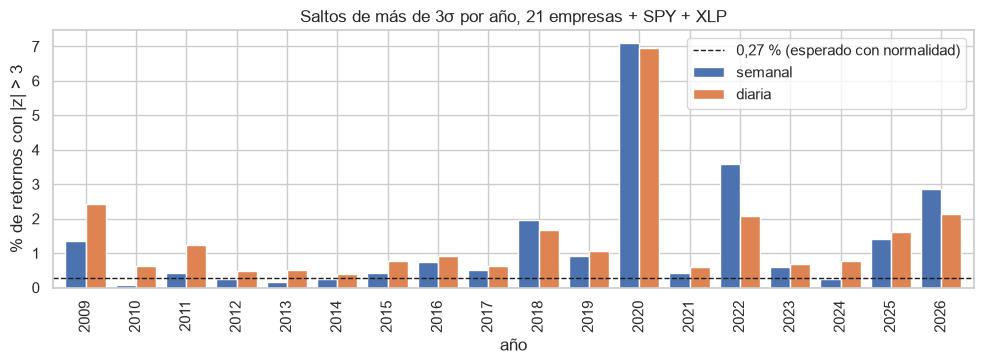

fecha     2009   2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020   2021   2022   2023   2024   2025   2026
semanal 1.3600 0.0800 0.4200 0.2500 0.1700 0.2500 0.4200 0.7500 0.5000 1.9700 0.9200 7.1100 0.4200 3.6000 0.5900 0.2500 1.4200 2.8600
diaria  2.4300 0.6400 1.2400 0.4900 0.5000 0.4000 0.7800 0.9100 0.6400 1.6800 1.0700 6.9600 0.5900 2.0800 0.6800 0.7600 1.6200 2.1300
Años con más saltos semanales: {2020: 85, 2022: 43, 2026: 27}


In [4]:
# Figura: % de retornos con |z| > 3 por año, en las dos instantáneas (¿los saltos son errores sueltos o episodios del mercado?)
pct_anio = pd.DataFrame({n: d.dropna(subset=["r"]).assign(s=lambda x: x.z.abs() > UMBRAL_SIGMA).groupby(d.fecha.dt.year).s.mean() * 100
                         for n, d in [("semanal", sem_r), ("diaria", dia_r)]})
fig, ax = plt.subplots(figsize=(10, 3.8))
pct_anio.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"], width=0.8)
ax.axhline(0.27, color="k", ls="--", lw=1, label="0,27 % (esperado con normalidad)")
ax.set_xlabel("año"); ax.set_ylabel("% de retornos con |z| > 3"); ax.legend()
ax.set_title("Saltos de más de 3σ por año, 21 empresas + SPY + XLP")
fig.tight_layout(); fig.savefig(cm.DIR_ASSETS / "nb02_saltos_precios.png", dpi=150, bbox_inches="tight"); plt.show()
print(pct_anio.round(2).T.to_string())
top = sem_r[sem_r.z.abs() > UMBRAL_SIGMA].assign(anio=lambda x: x.fecha.dt.year).anio.value_counts().head(3)
print("Años con más saltos semanales:", top.to_dict())

**Lectura (tabla).** Las dos instantáneas cubren los mismos 23 tickers desde enero de 2009, sin fechas faltantes, duplicados, nulos ni precios ≤ 0, y todas las fechas semanales son lunes. Hay un solo volumen igual a 0: CHD el 2019-12-31, un día en que la bolsa abrió, con el cierre idéntico al del día anterior (retorno 0,0000) y volumen normal antes y después; es un faltante que el proveedor rellenó, no un día sin negociación (T2).

**Lectura (figura).** Los saltos de más de 3σ son 272 semanales (1,28 % de los retornos) y 1.455 diarios (1,41 %), unas 5 veces el 0,27 % esperado con normalidad; la regla de 1,5·IQR marca más (4,02 % y 4,78 %) porque su umbral queda más cerca del centro. Se concentran en episodios del mercado: 7,11 % de las semanas de 2020, 3,60 % en 2022 y 2,86 % en 2026, frente a menos de 1 % en 10 de los 18 años.

**Justificación:** los saltos se conservan porque coinciden con episodios de todo el mercado y aparecen igual en las dos instantáneas, lo que descarta un error de una descarga; P1 y P6 estudian justamente esas colas. El volumen 0 de CHD se conserva y se declara: afecta un retorno diario de 4.474 y el volumen no entra en ninguna hipótesis.

### 1.1 Consistencia entre las dos tablas de precios (C9)

Las dos instantáneas se descargaron en momentos distintos y el precio ajustado por dividendos cambia cada vez que hay un dividendo nuevo (todo el pasado se multiplica por un factor). Por eso no se comparan **precios** sino **log-retornos**, que no dependen de ese factor. La diaria se remuestrea a semanas con el último cierre de cada semana (viernes) y se etiqueta con el lunes, como la semanal.

In [5]:
diaria_sem = cm.a_ancho(dia).resample("W-FRI").last()             # último cierre de cada semana (viernes)
diaria_sem.index = diaria_sem.index - pd.Timedelta(days=4)        # etiqueta del lunes, como la instantánea semanal
r_dia, r_sem = np.log(diaria_sem).diff(), np.log(cm.a_ancho(sem)).diff()
r_dia, r_sem = r_dia.align(r_sem, join="inner")
ambos = r_dia.notna() & r_sem.notna()
iguales = ((r_dia - r_sem).abs() < TOL_RETORNO) & ambos
c9 = pd.DataFrame({"semanas": ambos.sum(), "correlacion": [r_dia[t].corr(r_sem[t]) for t in r_dia],
                   "pct_iguales": 100 * iguales.sum() / ambos.sum()})
print(c9.describe().loc[["min", "50%", "max"]].round(6).to_string())
print(f"Total: {int(ambos.sum().sum()):,} semanas-ticker; correlación {pd.concat([r_dia.stack(), r_sem.stack()], axis=1).dropna().corr().iloc[0, 1]:.6f};",
      f"{100 * iguales.sum().sum() / ambos.sum().sum():.2f} % con diferencia < {100 * TOL_RETORNO:.1f} pp;",
      f"diferencia absoluta máxima {100 * (r_dia - r_sem).abs().max().max():.4f} pp")

     semanas  correlacion  pct_iguales
min 927.0000       1.0000     100.0000
50% 927.0000       1.0000     100.0000
max 927.0000       1.0000     100.0000
Total: 21,321 semanas-ticker; correlación 1.000000; 100.00 % con diferencia < 0.1 pp; diferencia absoluta máxima 0.0002 pp


**Lectura (C9).** En las 21.321 semanas-ticker comparables, el log-retorno semanal de la instantánea semanal y el de la diaria remuestreada coinciden en el 100,00 % de los casos con una diferencia menor de 0,1 pp (máxima 0,0002 pp), con correlación 1,000000 en total y en cada uno de los 23 tickers. Las dos tablas describen el mismo mercado: la diferencia de nivel entre sus precios ajustados es solo el factor de ajuste por dividendos, que se cancela en el retorno.

**Justificación:** se comparan retornos y no precios porque los precios ajustados de dos descargas hechas en fechas distintas difieren en un factor; con la consistencia verificada, nb03 puede usar la semanal para P1 y la diaria para P6 (y nb04 la diaria para P4) sin que el resultado dependa de cuál tabla se usó.

## 2. EDGAR: completitud concepto × empresa

Para cada uno de los 6 conceptos de los ratios y el [EPS](../docs/entrega_1/glosario.md) reportado (`cm.CONCEPTOS`) se mide la fracción de años fiscales con dato en la tabla anual. Un 0 % significa que la empresa **no reporta el concepto con ninguno de los nombres XBRL aceptados**, no que el valor sea cero (T2). Dimensión: completitud; nivel: columna.

Años fiscales 2009–2025: filas por empresa 17–19


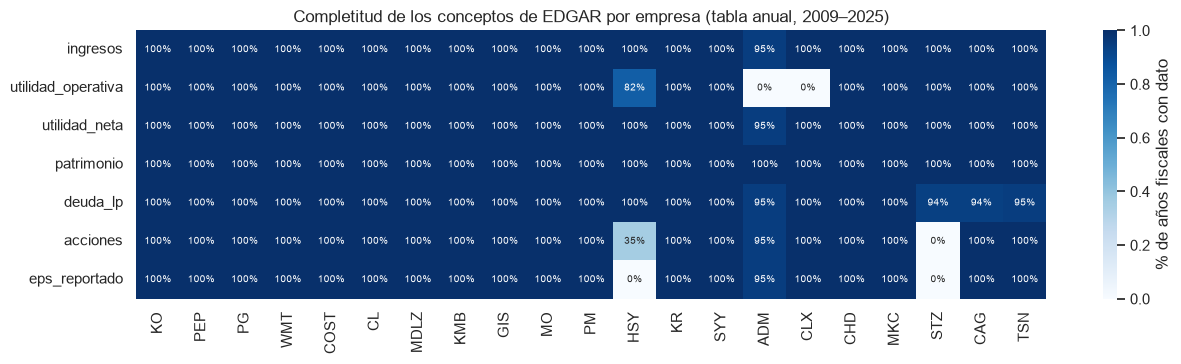

Celdas concepto × empresa por debajo de 100 %:
                    ticker
utilidad_operativa  ADM       0.0000
                    CLX       0.0000
acciones            STZ       0.0000
eps_reportado       HSY       0.0000
                    STZ       0.0000
acciones            HSY      35.0000
utilidad_operativa  HSY      82.0000
deuda_lp            STZ      94.0000
                    CAG      94.0000
ingresos            ADM      95.0000
utilidad_neta       ADM      95.0000
deuda_lp            ADM      95.0000
                    TSN      95.0000
acciones            ADM      95.0000
eps_reportado       ADM      95.0000


In [6]:
ANIOS = (pd.Timestamp(cm.INICIO).year, FECHA_INST.year - 1)        # años fiscales completos de la historia
a09 = anual[anual["end"].dt.year.between(*ANIOS)]
comp = a09.groupby("ticker")[list(cm.CONCEPTOS)].apply(lambda g: g.notna().mean()).T[EMPRESAS]
print(f"Años fiscales {ANIOS[0]}–{ANIOS[1]}: filas por empresa {a09.groupby('ticker').size().min()}–{a09.groupby('ticker').size().max()}")
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(comp, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, annot_kws={"size": 7},
            cbar_kws={"label": "% de años fiscales con dato"}, ax=ax)
ax.set_title(f"Completitud de los conceptos de EDGAR por empresa (tabla anual, {ANIOS[0]}–{ANIOS[1]})"); ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(cm.DIR_ASSETS / "completitud_edgar.png", dpi=150, bbox_inches="tight"); plt.show()
incompletas = comp.stack()[lambda s: s < 1].sort_values()
print("Celdas concepto × empresa por debajo de 100 %:"); print((100 * incompletas).round(0).to_string())

In [7]:
# Vacíos conocidos, con sus años
print("Sin utilidad operativa (sin margen operativo):", [t for t in EMPRESAS if comp.loc["utilidad_operativa", t] == 0])
for t in ["PM", "SYY", "TSN", "CAG", "STZ", "ADM"]:
    print(f"  {t}: años sin deuda_lp ->", a09[(a09.ticker == t) & a09.deuda_lp.isna()]["end"].dt.year.tolist())
print("Años con EPS anual por empresa (STZ y HSY):", rat_anual[rat_anual["end"].dt.year.between(*ANIOS)].dropna(subset=["eps"])
      .groupby("ticker")["end"].agg(lambda s: f"{s.dt.year.min()}–{s.dt.year.max()} ({len(s)})").reindex(["STZ", "HSY"]).fillna("ninguno").to_dict())
print("Filas con acciones implícitas: anual", int(anual.acciones_implicitas.sum()), anual[anual.acciones_implicitas].groupby("ticker")["end"].agg(lambda s: f"{s.dt.year.min()}–{s.dt.year.max()}").to_dict(), "| TTM", int(ttm.acciones_implicitas.sum()))
dup = a09.assign(anio=a09["end"].dt.year)[lambda d: d.duplicated(["ticker", "anio"], keep=False)]
print("Años fiscales con dos cierres (consistencia, nivel tabla):"); print(dup[["ticker", "end", "utilidad_neta"]].to_string(index=False))

# Nombres alternativos (consistencia, nivel columna): años-empresa cuyo dato anual solo existe con un nombre que no es el primero
fy = hechos[(hechos.form == "10-K") & (hechos.fp == "FY")]
alt = {}
for c, (nombres, _) in cm.CONCEPTOS.items():
    con_principal = set(map(tuple, fy[fy.concepto == nombres[0]][["ticker", "end"]].values))
    filas = a09.dropna(subset=[c])[["ticker", "end"]]
    usa_alt = filas[[(t, e) not in con_principal for t, e in filas.values]]
    alt[c] = {"años_empresa": len(usa_alt), "empresas": sorted(usa_alt.ticker.unique())}
print(pd.DataFrame(alt).T.to_string())

# EPS ≤ 0: el P/E no tiene sentido (T2, violación de dominio del P/E)
print("EPS anual ≤ 0:", rat_anual[rat_anual.eps <= 0].groupby("ticker")["end"].agg(lambda s: list(s.dt.date.astype(str))).to_dict())
print("EPS TTM ≤ 0:", int((ttm.eps_ttm <= 0).sum()), "trimestres;", ttm[ttm.eps_ttm <= 0].groupby("ticker").size().to_dict())

Sin utilidad operativa (sin margen operativo): ['ADM', 'CLX']
  PM: años sin deuda_lp -> []
  SYY: años sin deuda_lp -> []
  TSN: años sin deuda_lp -> [2009]
  CAG: años sin deuda_lp -> [2009]
  STZ: años sin deuda_lp -> [2009]
  ADM: años sin deuda_lp -> [2018]
Años con EPS anual por empresa (STZ y HSY): {'STZ': 'ninguno', 'HSY': '2009–2014 (6)'}
Filas con acciones implícitas: anual 9 {'CAG': '2008–2008', 'CL': '2007–2007', 'GIS': '2008–2008', 'KMB': '2007–2007', 'MDLZ': '2007–2007', 'MKC': '2008–2008', 'MO': '2007–2007', 'PEP': '2007–2007', 'PM': '2007–2007'} | TTM 0
Años fiscales con dos cierres (consistencia, nivel tabla):
ticker        end   utilidad_neta
   ADM 2012-06-30 1223000000.0000
   ADM 2012-12-31 1375000000.0000
   ADM 2018-01-01             NaN
   ADM 2018-12-31 1810000000.0000
   TSN 2009-09-30 -547000000.0000
   TSN 2009-10-03 -547000000.0000
   TSN 2010-09-30  780000000.0000
   TSN 2010-10-02  780000000.0000
                   años_empresa                            

**Lectura (mapa de calor).** De las 147 celdas concepto × empresa (7 × 21), 5 están en 0 %: ADM y CLX no reportan utilidad operativa (no tienen margen operativo), STZ no tiene acciones ni EPS reportado (los publica por clase de acción, desglose que `companyfacts` no trae) y HSY no tiene EPS reportado. HSY además solo tiene acciones en el 35 % de los años (EPS anual 2009–2014). Después de los nombres alternativos, faltan 4 años-empresa de deuda: 2009 en TSN, CAG y STZ, y la fila de ADM con cierre 2018-01-01, que no tiene ningún flujo. Hay 9 filas anuales con acciones implícitas, todas anteriores a 2009, y ninguna en el [TTM](../docs/entrega_1/glosario.md).

**Consistencia.** Los nombres alternativos cubren 372 años-empresa (196 de ingresos y 115 de deuda): son sinónimos del mismo concepto (nivel columna). Aparecen además años fiscales con dos cierres (duplicados aproximados, nivel tabla): ADM 2012 (cambió su cierre fiscal de junio a diciembre: hay un año a junio y otro a diciembre) y ADM 2018 (una fila con cierre 2018-01-01 sin flujos) y TSN 2009–2010 (el mismo año con fin el 30 de septiembre y el sábado más cercano). **EPS ≤ 0:** 8 filas anuales (7 años distintos; TSN 2009 aparece dos veces) y 22 trimestres de EPS TTM (CAG 10, TSN 4, MO 3, SYY 3, GIS 2) tienen utilidad negativa.

**Justificación:** un concepto ausente queda NaN y el ratio que lo usa queda vacío; no se imputa porque la imputación del curso (media, mediana, KNN) inventaría utilidades o deudas de una empresa concreta, y un 0 contable no es lo mismo que "no reportado" (T2). El [P/E](../docs/entrega_1/glosario.md) con EPS ≤ 0 se deja vacío porque viola el dominio del ratio (un precio sobre una pérdida no se interpreta como "barato"). Los duplicados aproximados se conservan porque cada fila se usa por su `end` y su `filed`, y el análisis principal usa `ratios_ttm`, que tiene una fila por trimestre.

## 2b. Calidad del EPS TTM (`tabla_trimestral` y `ratios_ttm`, R6)

El [EPS](../docs/entrega_1/glosario.md) de los últimos 12 meses (TTM) suma 4 trimestres que vienen de reportes distintos, y el cuarto trimestre no tiene [10-Q](../docs/entrega_1/glosario.md): se deriva como año − (Q1 + Q2 + Q3). Eso cambia qué se puede verificar:

- **Si el Q4 es derivado**, Q1 + Q2 + Q3 + Q4 = año **por construcción**: comparar el [TTM](../docs/entrega_1/glosario.md) del cierre fiscal con el dato anual es tautológico y no verifica nada. Para esos Q4 se revisa otra cosa: que sean plausibles (chequeo 2).
- **Si los 4 trimestres son reportados** (la mayoría: el [10-K](../docs/entrega_1/glosario.md) suele traer también el cuarto trimestre por separado), la suma puede no coincidir con el año, y la comparación sí es una verificación (chequeo 8).

Los 9 chequeos llevan su dimensión, su nivel, una lectura con cifras y su "Justificación:".

### Chequeo 1. Completitud del TTM por empresa (completitud, nivel columna)

Desde el primer TTM posible de cada empresa (su primera fila en `ratios_ttm`), qué % de los trimestres tiene `eps_ttm`, y por qué falta en los demás: un trimestre faltante, un Q4 que no se pudo derivar (falta un trimestre del año fiscal), acciones ausentes o implícitas; aparte se cuentan los TTM ≤ 0, que existen pero dejan el [P/E](../docs/entrega_1/glosario.md) vacío.

In [8]:
un_trim = trim[trim.concepto == "utilidad_neta"]
fines_un = un_trim.groupby("ticker")["end"].apply(set)
def causa_ttm(r):
    """Por qué una fila de ratios_ttm no tiene EPS TTM utilizable para el P/E."""
    if pd.notna(r.eps_ttm):
        return "TTM ≤ 0" if r.eps_ttm <= 0 else "con TTM > 0"
    if pd.isna(r.utilidad_neta_ttm):
        # ¿algún cierre fiscal (10-K) de los últimos 12 meses no tiene trimestre? → Q4 no derivable
        cierres = anual[(anual.ticker == r.ticker) & anual["end"].between(r["end"] - pd.Timedelta(days=DUR_ANUAL[0]), r["end"])]["end"]
        return "Q4 no derivable" if any(e not in fines_un.get(r.ticker, set()) for e in cierres) else "trimestre faltante"
    if pd.isna(r.acciones):
        return "acciones ausentes"
    return "acciones implícitas" if r.acciones_implicitas else "otro"
ttm["causa"] = ttm.apply(causa_ttm, axis=1)
c1 = pd.crosstab(ttm.ticker, ttm.causa)
c1["% con TTM"] = 100 * (c1.get("con TTM > 0", 0) + c1.get("TTM ≤ 0", 0)) / c1.sum(axis=1)
print(c1.sort_values("% con TTM").round(1).to_string())
print("Totales por causa:", ttm.causa.value_counts().to_dict(), "| filas:", len(ttm))
print("Mediana del % con TTM:", round(c1["% con TTM"].median(), 1), "| sin STZ ni HSY:", round(c1["% con TTM"].drop(["STZ", "HSY"]).median(), 1))

causa   Q4 no derivable  TTM ≤ 0  acciones ausentes  con TTM > 0  trimestre faltante  % con TTM
ticker                                                                                         
STZ                   2        0                 63            0                   0     0.0000
HSY                   2        0                 42           20                   8    27.8000
CHD                   0        0                  0           60                  12    83.3000
TSN                   7        4                  0           57                   5    83.6000
CAG                   0       10                  0           56                   6    91.7000
MDLZ                  2        0                  0           66                   0    97.1000
KR                    2        0                  0           67                   0    97.1000
WMT                   2        0                  0           67                   0    97.1000
CL                    2        0        

**Lectura.** De 1.448 filas de `ratios_ttm`, 1.287 (88,9 %) tienen EPS TTM: 1.265 positivos y 22 ≤ 0. La mediana por empresa es 98,5 %; 6 empresas llegan a 100 %. Las faltas se concentran en dos empresas por limitaciones de la fuente: STZ (0 %, 63 trimestres sin acciones) y HSY (27,8 %, 42 trimestres sin acciones después de 2015). El resto son 31 trimestres faltantes (CHD 12, HSY 8, CAG 6, TSN 5) y 25 Q4 no derivables, casi todos al inicio de la historia de cada empresa (1–2 por empresa; TSN 7).

**Justificación:** un TTM vacío no se rellena (T2): sumar 3 trimestres o poner 0 en el que falta daría un EPS falso. STZ queda fuera de P2 y P3 y HSY solo entra con su historia hasta 2015; se declara como limitación de completitud.

### Chequeo 2. Plausibilidad del Q4 derivado (precisión / validez, nivel registro)

Para cada Q4 derivado (`origen == "q4_derivado"`) de la utilidad neta y de los ingresos: (a) ¿tiene signo contrario al del año cuando Q1–Q3 son positivos? y (b) ¿queda fuera del rango [mínimo, máximo] de los trimestres **reportados** de esa empresa, ampliado por la mitad del ancho del rango?

In [9]:
casos_q4 = []
for (t, c), g in trim[trim.concepto.isin(["utilidad_neta", "ingresos"])].sort_values("end").groupby(["ticker", "concepto"]):
    g = g.reset_index(drop=True)
    rep = g.loc[g.origen == "reportado", "val"]
    lo, hi = rep.min(), rep.max(); m = AMPLIACION_RANGO * (hi - lo)
    for i in g.index[g.origen == "q4_derivado"]:
        prev = g.iloc[max(0, i - 3):i]                                   # Q1–Q3 del mismo año fiscal
        q4 = g.at[i, "val"]; anio = q4 + prev.val.sum()
        signo = len(prev) == 3 and (prev.val > 0).all() and np.sign(q4) != np.sign(anio)
        rango = q4 < lo - m or q4 > hi + m
        if signo or rango:
            f10k = anual[(anual.ticker == t) & (anual["end"] == g.at[i, "end"])].filed_utilidad_neta.iloc[0]   # publicación del 10-K
            casos_q4.append({"ticker": t, "end": g.at[i, "end"].date(), "año": anio / 1e6,
                             "Q1–Q3": " / ".join(f"{x / 1e6:,.0f}" for x in prev.val), "Q4": q4 / 1e6,
                             "Q4 ÷ año": q4 / anio, "rango_rep": f"[{lo / 1e6:,.0f}; {hi / 1e6:,.0f}]",
                             "(a) signo": signo, "(b) rango": rango, "filed_10k": f10k.date(),
                             "dias_Q4": (g.at[i, "end"] - g.at[i, "start"]).days, "concepto": c})
casos_q4 = pd.DataFrame(casos_q4)
n_q4 = trim[trim.concepto.isin(["utilidad_neta", "ingresos"]) & (trim.origen == "q4_derivado")].groupby("concepto").size()
print("Q4 derivados revisados:", n_q4.to_dict(), "| casos:", len(casos_q4))
print("Cifras en millones de USD:"); print(casos_q4.drop(columns="concepto").round(2).to_string(index=False))
# Fuente de cada caso: lista de 10-K de la empresa en EDGAR hasta la fecha de publicación (el primero de la lista es el del año)
CIK = {"CAG": 23217, "CHD": 313927, "CL": 21665, "KMB": 55785, "KO": 21344, "PEP": 77476, "PM": 1413329, "WMT": 104169}
for _, r in casos_q4.iterrows():
    print(f"  {r.ticker} {r['end']}: https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK={CIK.get(r.ticker, r.ticker)}"
          f"&type=10-K&dateb={r.filed_10k:%Y%m%d}&count=1")

Q4 derivados revisados: {'ingresos': 145, 'utilidad_neta': 138} | casos: 10
Cifras en millones de USD:
ticker        end        año                 Q1–Q3         Q4  Q4 ÷ año       rango_rep  (a) signo  (b) rango  filed_10k  dias_Q4
   CAG 2024-05-26   347.2000       320 / 286 / 309  -567.3000   -1.6300   [-1,154; 482]       True      False 2024-07-11       90
   CHD 2022-12-31   413.9000       204 / 187 / 187  -164.7000   -0.4000      [-75; 406]       True      False 2023-02-16       91
    CL 2025-12-31  2132.0000       690 / 743 / 735   -36.0000   -0.0200     [-458; 743]       True      False 2026-02-23       91
   KMB 2014-12-31  1526.0000       538 / 509 / 562   -83.0000   -0.0500     [-305; 907]       True      False 2015-02-18       91
    KO 2010-12-31 11809.0000 1,614 / 2,369 / 2,055  5771.0000    0.4900  [1,046; 3,924]      False       True 2011-02-28       90
    KO 2017-12-31  1248.0000 1,182 / 1,371 / 1,447 -2752.0000   -2.2100  [1,046; 3,924]       True       True 2018-02

**Lectura.** De 138 Q4 derivados de utilidad neta y 145 de ingresos, 10 casos (todos de utilidad neta) caen fuera de lo esperado. Cada uno se explica con sus componentes en la instantánea (millones de USD) y su fuente es el 10-K enlazado arriba, publicado en la fecha `filed_10k`:

| Caso | Qué muestran los componentes |
|---|---|
| CAG 2024-05 | Q1–Q3 normales (286 a 320); el año cae a 347, así que el Q4 da −567 (1,6 veces el año, con signo contrario): una pérdida concentrada en el cuarto trimestre |
| CHD 2022-12 | Q1–Q3 de 187 a 204; año 414; Q4 −165 (−40 % del año) |
| CL 2025-12 | Q1–Q3 de 690 a 743; año 2.132; Q4 −36: un cuarto trimestre casi en equilibrio (−2 % del año) |
| KMB 2014-12 | Q1–Q3 de 509 a 562; año 1.526; Q4 −83 (−5 % del año) |
| KO 2010-12 | Q1–Q3 de 1.614 a 2.369; año 11.809; Q4 +5.771 (49 % del año, 1,5 veces el máximo reportado): una ganancia concentrada en el cuarto trimestre |
| KO 2017-12 | Q1–Q3 de 1.182 a 1.447; año 1.248; Q4 −2.752 (2,2 veces el año, signo contrario) |
| PEP 2017-12 | Q1–Q3 de 1.318 a 2.144; año 4.857; Q4 −710 (−15 % del año) |
| PEP 2018-12 | Q1–Q3 de 1.343 a 2.498; año 12.515; Q4 +6.854 (55 % del año, 1,6 veces el máximo reportado) |
| PM 2024-12 | Q1–Q3 de 2.148 a 3.082; año 7.057; Q4 −579 (−8 % del año) |
| WMT 2021-01 | Q1–Q3 de 3.990 a 6.476; año 13.510; Q4 −2.091 (−15 % del año) |

En los 10 casos Q1–Q3 son positivos y están dentro del rango habitual de la empresa, el año completo es positivo y los dos insumos son cifras publicadas sin corrección de escala (chequeo 9). Por eso la diferencia está en el cuarto trimestre mismo y no en un error de suma. Las duraciones son normales: 90–92 días, y 111 en PEP, cuyo cuarto trimestre fiscal tiene 16 semanas. La causa contable de cada caso (cargo, ganancia o impuesto) se lee en el 10-K enlazado; no está en esta instantánea.

**Justificación:** los 10 Q4 se conservan porque provienen de cifras publicadas y coherentes con el año: el EPS TTM de esos trimestres es el que vio el inversor, y borrarlos haría que el P/E pareciera más estable de lo que fue. Si un Q4 viniera de un error de etiqueta (un año o un trimestre en otra escala o con otro nombre XBRL), su TTM se dejaría vacío; no hay ninguno.

### Chequeo 3. Triangulación del EPS TTM con yfinance (credibilidad, nivel varias tablas)

El EPS TTM más reciente de cada empresa (ajustado por los [splits](../docs/entrega_1/glosario.md) posteriores a su `filed`, para estar en la escala de hoy) frente al `trailingEps` de yfinance `info`. Antes de explicar una diferencia se separa la causa "TTM no actualizado": su `filed` tiene más de 120 días frente a la fecha de la instantánea.

In [10]:
def factor_split(t, desde):
    """Producto de los splits de la empresa posteriores a una fecha (1 si no hubo)."""
    return splits[(splits.ticker == t) & (splits.fecha > desde)].ratio.prod()
ult_ttm = ttm.dropna(subset=["eps_ttm"]).sort_values("filed_eps_ttm").groupby("ticker").tail(1).set_index("ticker")
c3 = ult_ttm[["end", "filed_eps_ttm"]].copy()
c3["eps_ttm"] = [ult_ttm.at[t, "eps_ttm"] / factor_split(t, ult_ttm.at[t, "filed_eps_ttm"]) for t in c3.index]
c3["trailingEps"] = info.set_index("ticker").trailingEps
c3["dias"] = (FECHA_INST - c3.filed_eps_ttm).dt.days
c3["dif_rel"] = c3.eps_ttm / c3.trailingEps - 1
c3["causa"] = np.where(c3.dias > DIAS_RECIENTE, "TTM no actualizado", np.where(c3.dif_rel.abs() > DIF_TRIANGULACION, "otra (se explica)", "coincide"))
print(c3.sort_values("dif_rel").round(3).to_string())
act = c3[c3.dias <= DIAS_RECIENTE]
print(f"Empresas comparadas: {len(c3)} (STZ no tiene EPS TTM) | mediana dif. relativa: todas {c3.dif_rel.median():+.3f};",
      f"solo actualizadas ({len(act)}) {act.dif_rel.median():+.3f} | |dif| > {DIF_TRIANGULACION:.0%}: {int((c3.dif_rel.abs() > DIF_TRIANGULACION).sum())}")
# KMB: ¿la diferencia viene de EDGAR o de la definición de yfinance? Suma de los 4 EPS que KMB reportó en sus propios 10-Q
k = trim[(trim.ticker == "KMB") & (trim.concepto == "eps_reportado")].sort_values("end").tail(4)
print("KMB: suma de los 4 EPS reportados", round(k.val.sum(), 2), "| fines", list(k["end"].dt.date.astype(str)))
print("Último 10-K de CLX en la instantánea:", hechos[(hechos.ticker == "CLX") & (hechos.form == "10-K")].filed.max().date())

              end filed_eps_ttm  eps_ttm  trailingEps  dias  dif_rel               causa
ticker                                                                                  
HSY    2015-12-31    2016-02-26   2.3970       7.3700  3884  -0.6750  TTM no actualizado
MDLZ   2026-03-31    2026-04-28   2.0290       2.7700   170  -0.2680  TTM no actualizado
KO     2026-04-03    2026-04-30   3.1760       3.3300   168  -0.0460  TTM no actualizado
KR     2026-08-15    2026-09-18   1.7850       1.8700    27  -0.0460            coincide
WMT    2026-07-31    2026-08-28   2.7670       2.8600    48  -0.0320            coincide
CL     2026-06-30    2026-07-31   2.5420       2.6200    76  -0.0300            coincide
PM     2026-06-30    2026-07-24   6.9710       7.1800    83  -0.0290            coincide
COST   2026-08-30    2026-10-07  20.7590      21.3600     8  -0.0280            coincide
CHD    2026-06-30    2026-07-31   3.1270       3.2000    76  -0.0230            coincide
PG     2026-06-30    

**Lectura.** De 20 empresas comparables (STZ no tiene EPS TTM), 16 tienen su último TTM publicado hace 120 días o menos y en todas ellas la diferencia con `trailingEps` es menor de 5 %, salvo KMB; la mediana es −1,4 % en las actualizadas y −1,9 % en las 20. Hay 4 diferencias de más de 10 %:
- **TTM no actualizado (3):** HSY (−67,5 %; su EPS se detiene en 2015, hace 3.884 días), MDLZ (−26,8 %; 170 días) y CLX (+28,3 %; 168 días; el último 10-K de CLX en `companyfacts` es de 2025-08-08). KO también está desactualizada (168 días), pero su diferencia es pequeña (−4,6 %). Son los casos de frescura de la fuente documentados en nb01: la SEC aún no incorporó los reportes posteriores.
- **Definición (1):** KMB (+14,3 %). La suma de los 4 EPS que KMB reportó en sus propios 10-Q da 5,88, igual a nuestro 5,87: EDGAR es coherente consigo mismo y la diferencia viene de cómo yfinance arma su `trailingEps`, cuya fórmula no publica; la causa exacta no se puede verificar con la instantánea.

**Justificación:** se usa EDGAR porque es la fuente oficial, con fecha de publicación, y su EPS coincide con el de yfinance en 15 de las 16 empresas actualizadas. La falta de actualización de KO, MDLZ y CLX se declara (disponibilidad) y no se completa con otra fuente, para no mezclar definiciones; la regla de antigüedad máxima (548 días, D5) deja fuera a HSY después de 2017.

### Chequeo 4. Verificación manual contra el 10-Q publicado (precisión, nivel atributo)

Dos trimestres de tres empresas: KO (año calendario), WMT (cierra en enero) y GIS (cierra en mayo). Las cifras se leyeron a mano del estado de resultados de cada 10-Q en EDGAR (millones de USD y de acciones); la URL va en la tabla. Para GIS 2025-11-23 el estado de resultados no trae las acciones (están en la nota de EPS, que no se leyó): esa celda queda vacía.

In [11]:
# Cifras leídas a mano del 10-Q publicado: (utilidad neta, acciones diluidas promedio, EPS diluido), millones salvo el EPS
EDGAR = "https://www.sec.gov/Archives/edgar/data/"
manual = pd.DataFrame([
    ("KO", "2025-06-27", 3_810, 4_315, 0.88, EDGAR + "21344/000002134425000061/ko-20250627.htm"),
    ("KO", "2025-09-26", 3_696, 4_313, 0.86, EDGAR + "21344/000162828025046054/ko-20250926.htm"),
    ("WMT", "2026-04-30", 5_330, 7_999, 0.67, EDGAR + "104169/000010416926000102/wmt-20260430.htm"),
    ("WMT", "2026-07-31", 6_366, 7_978, 0.80, EDGAR + "104169/000010416926000154/wmt-20260731.htm"),
    ("GIS", "2025-11-23", 413.0, np.nan, 0.78, EDGAR + "40704/000162828025057598/gis-20251123.htm"),
    ("GIS", "2026-08-30", 397.0, 537.9, 0.74, EDGAR + "40704/000162828026063201/gis-20260830.htm"),
], columns=["ticker", "end", "un_10q", "acc_10q", "eps_10q", "url"]).assign(end=lambda d: pd.to_datetime(d["end"]))
nuestro = trim.pivot_table(index=["ticker", "end"], columns="concepto", values="val", aggfunc="first")
v = manual.join(nuestro[["utilidad_neta", "acciones", "eps_reportado"]], on=["ticker", "end"])
v["dif_un"] = v.utilidad_neta / 1e6 / v.un_10q - 1
v["dif_acc"] = v.acciones / 1e6 / v.acc_10q - 1
v["dif_eps"] = v.eps_reportado / v.eps_10q - 1
v["eps_calc"] = v.utilidad_neta / v.acciones                      # el que usa el TTM: utilidad ÷ acciones
print(v[["ticker", "end", "un_10q", "acc_10q", "eps_10q", "dif_un", "dif_acc", "dif_eps", "eps_calc"]].round(4).to_string(index=False))
print("Máxima |diferencia| en utilidad, acciones y EPS:", v[["dif_un", "dif_acc", "dif_eps"]].abs().max().round(4).to_dict())
for _, r in v.iterrows(): print(f"  {r.ticker} {r['end'].date()}: {r.url}")

ticker        end    un_10q   acc_10q  eps_10q  dif_un  dif_acc  dif_eps  eps_calc
    KO 2025-06-27 3810.0000 4315.0000   0.8800  0.0000   0.0000   0.0000    0.8830
    KO 2025-09-26 3696.0000 4313.0000   0.8600  0.0000   0.0000   0.0000    0.8569
   WMT 2026-04-30 5330.0000 7999.0000   0.6700  0.0000   0.0000   0.0000    0.6663
   WMT 2026-07-31 6366.0000 7978.0000   0.8000  0.0000   0.0000   0.0000    0.7979
   GIS 2025-11-23  413.0000       NaN   0.7800  0.0000      NaN   0.0000    0.7687
   GIS 2026-08-30  397.0000  537.9000   0.7400  0.0000   0.0000   0.0000    0.7381
Máxima |diferencia| en utilidad, acciones y EPS: {'dif_un': 0.0, 'dif_acc': 0.0, 'dif_eps': 0.0}
  KO 2025-06-27: https://www.sec.gov/Archives/edgar/data/21344/000002134425000061/ko-20250627.htm
  KO 2025-09-26: https://www.sec.gov/Archives/edgar/data/21344/000162828025046054/ko-20250926.htm
  WMT 2026-04-30: https://www.sec.gov/Archives/edgar/data/104169/000010416926000102/wmt-20260430.htm
  WMT 2026-07-31: https:/

**Lectura.** En los 6 trimestres revisados (KO 2025-06 y 2025-09; WMT 2026-04 y 2026-07, año fiscal que cierra en enero; GIS 2025-11 y 2026-08, año fiscal que cierra en mayo), la utilidad neta, las acciones diluidas y el EPS de `tabla_trimestral` coinciden exactamente con el 10-Q publicado (diferencia 0,0000 en los 17 valores comparados). El EPS que usa el TTM (utilidad ÷ acciones) difiere del publicado solo por redondeo: KO 0,883 frente a 0,88 y WMT 0,666 frente a 0,67.

**Justificación:** la verificación manual confirma que la ingesta (nombres XBRL, primera publicación y escala) reproduce el reporte que leyó el inversor, también en empresas con año fiscal no calendario. No requiere ninguna corrección.

### Chequeo 5. Años fiscales distintos del calendario (consistencia entre empresas, nivel tabla)

Mes de cierre del año fiscal de cada empresa: la moda del mes de `end` de sus hechos anuales (10-K, duración de un año).

In [12]:
k10 = hechos[(hechos.form == "10-K") & hechos.start.notna()]
k10 = k10[(k10["end"] - k10.start).dt.days.between(*DUR_ANUAL)].drop_duplicates(["ticker", "end"])
mes_cierre = k10.groupby("ticker")["end"].agg(lambda s: s.dt.month.mode().iloc[0]).reindex(EMPRESAS)
meses_distintos = k10.groupby("ticker")["end"].agg(lambda s: sorted(s.dt.month.unique()))
print(pd.DataFrame({"mes_cierre": mes_cierre, "meses_observados": meses_distintos}).sort_values("mes_cierre").to_string())
no_dic = mes_cierre[mes_cierre != 12]
print(f"Empresas que no cierran en diciembre: {len(no_dic)} de {len(EMPRESAS)} ->", no_dic.index.tolist())

        mes_cierre meses_observados
ticker                             
KR               1           [1, 2]
WMT              1              [1]
STZ              2              [2]
GIS              5              [5]
CAG              5              [5]
SYY              6           [6, 7]
CLX              6              [6]
PG               6              [6]
COST             8           [8, 9]
TSN              9          [9, 10]
MKC             11             [11]
CHD             12          [1, 12]
PM              12             [12]
PEP             12             [12]
MDLZ            12             [12]
KO              12             [12]
KMB             12             [12]
HSY             12             [12]
CL              12             [12]
MO              12             [12]
ADM             12          [6, 12]
Empresas que no cierran en diciembre: 11 de 21 -> ['PG', 'WMT', 'COST', 'GIS', 'KR', 'SYY', 'CLX', 'MKC', 'STZ', 'CAG', 'TSN']


**Lectura.** 11 de las 21 empresas no cierran su año fiscal en diciembre: WMT y KR en enero, STZ en febrero, GIS y CAG en mayo, PG, CLX y SYY en junio, COST en agosto, TSN en septiembre y MKC en noviembre. Algunas cambian de mes entre años por los calendarios de 52/53 semanas (KR enero/febrero, SYY junio/julio, COST agosto/septiembre, TSN septiembre/octubre, CHD diciembre/enero), y ADM cambió su cierre de junio a diciembre en 2012.

**Justificación:** todo se alinea por la fecha de cierre (`end`) y la de publicación (`filed`), nunca por año calendario ni por "Q1–Q4": el "Q1" de WMT termina en abril y el de KO en marzo, y compararlos como si fueran el mismo trimestre mezclaría meses distintos. En P2 y P3 cada empresa entra en cada fecha trimestral con el último dato publicado hasta ese día.

### Chequeo 6. Duraciones fuera de los filtros (conformidad, nivel atributo)

nb01 acepta como trimestre un hecho de 80–120 días, como acumulado del año uno de 80–329 y como año uno de 330–400. Se cuentan los hechos de los flujos (10-Q y 10-K con `start`) con duraciones entre 120 y 150 días o menores de 80, y se muestra la distribución completa de duraciones.

In [13]:
nombres_flujo = sum((cm.CONCEPTOS[c][0] for c in ["utilidad_neta", "ingresos", "utilidad_operativa", "acciones", "eps_reportado"]), [])
fl = hechos[hechos.form.isin(["10-Q", "10-K"]) & hechos.start.notna() & hechos.concepto.isin(nombres_flujo)].copy()
fl["dur"] = (fl["end"] - fl.start).dt.days
fl = fl.drop_duplicates(["ticker", "concepto", "start", "end"])
fuera = fl[(fl.dur < DUR_TRIMESTRE[0]) | fl.dur.between(DUR_TRIMESTRE[1] + 1, 150)]
print(f"Hechos de flujos: {len(fl):,} | < {DUR_TRIMESTRE[0]} días: {int((fl.dur < DUR_TRIMESTRE[0]).sum())} | 121–150 días: {int(fl.dur.between(121, 150).sum())}")
print(pd.cut(fl.dur, [0, 79, 120, 150, 179, 200, 260, 290, 329, 400, 5000]).value_counts().sort_index().to_string())
# Ejemplos de los bordes: los trimestres más largos aceptados (16 semanas) y los acumulados de 24 semanas
print(fl[fl.dur.between(110, 120)].groupby("ticker").size().to_dict())
print(fl[fl.dur.between(150, 179)].groupby("ticker").size().to_dict())
print(fl[fl.dur.between(110, 120) | fl.dur.between(150, 179)].sort_values("dur").groupby("dur").head(1)[["ticker", "concepto", "start", "end", "dur", "form"]].head(4).to_string(index=False))

Hechos de flujos: 18,784 | < 80 días: 0 | 121–150 días: 0
dur
(0, 79]           0
(79, 120]      9968
(120, 150]        0
(150, 179]      409
(179, 200]     2470
(200, 260]      329
(260, 290]     2516
(290, 329]        0
(329, 400]     3092
(400, 5000]       0
{'COST': 106, 'KR': 158, 'PEP': 10}
{'CHD': 8, 'COST': 161, 'HSY': 15, 'KO': 65, 'PEP': 160}
ticker                                      concepto      start        end  dur form
  COST                                 NetIncomeLoss 2011-05-09 2011-08-28  111 10-K
  COST WeightedAverageNumberOfSharesOutstandingBasic 2012-05-07 2012-09-02  118 10-K
  COST                               SalesRevenueNet 2017-09-04 2018-02-18  167 10-Q
   CHD                         EarningsPerShareBasic 2009-01-01 2009-06-26  176 10-Q


**Lectura.** De 18.784 hechos de flujos con fecha de inicio, ninguno dura menos de 80 días ni entre 121 y 150: todos caen en uno de los filtros de nb01 (9.968 trimestres de 80–120 días, 5.724 acumulados de 150–290 días y 3.092 años de 330–400). Los bordes son los esperados por los calendarios de 52/53 semanas: trimestres de 16 semanas (111–118 días) en KR, COST y PEP, que el filtro de 80–120 acepta (por ejemplo, COST `NetIncomeLoss` del 2011-05-09 al 2011-08-28, 111 días), y acumulados de 24 semanas (150–179 días) en COST, PEP, KO, HSY y CHD, que el filtro de acumulados acepta (por ejemplo, COST `SalesRevenueNet` del 2017-09-04 al 2018-02-18, 167 días).

**Justificación:** como ningún hecho queda fuera, no hace falta ampliar los filtros; se conservan los de nb01 (80–120 y 330–400 días), que aceptan los trimestres de 12 o 16 semanas y los años de 52 o 53 semanas sin admitir un semestre como trimestre.

### Chequeo 7. Origen de los trimestres (procesabilidad, nivel columna)

Cuánto de la tabla trimestral viene tal cual de un reporte y cuánto es calculado: `reportado` (dato de ~90 días), `resta_ytd` (resta de acumulados), `q4_derivado` (año − Q1 − Q2 − Q3), `promedio_anual` (acciones del cierre fiscal tomadas del promedio anual del 10-K) y `saldo` (patrimonio y deuda, una foto en la fecha de cierre).

In [14]:
c7 = pd.crosstab(trim.concepto, trim.origen, margins=True, margins_name="total")
print(c7.to_string())
calc = trim[trim.concepto.isin(["utilidad_neta", "acciones"])]
pct_calc = 100 * (~calc.origen.isin(["reportado"])).groupby(calc.concepto).mean()
print("% calculado (no reportado tal cual):", pct_calc.round(1).to_dict())
print("Empresas con Q4 derivado de la utilidad neta:", trim[(trim.concepto == "utilidad_neta") & (trim.origen == "q4_derivado")].ticker.nunique())

origen              promedio_anual  q4_derivado  reportado  resta_ytd  saldo  total
concepto                                                                           
acciones                       321            0       1061          0      0   1382
deuda_lp                         0            0          0          0   1421   1421
eps_reportado                    0          135       1234          2      0   1371
ingresos                         0          145       1365          0      0   1510
patrimonio                       0            0          0          0   1502   1502
utilidad_neta                    0          138       1373          0      0   1511
utilidad_operativa               0          229       1098          0      0   1327
total                          321          647       6131          2   2923  10024
% calculado (no reportado tal cual): {'acciones': 23.2, 'utilidad_neta': 9.1}
Empresas con Q4 derivado de la utilidad neta: 21


**Lectura.** De 10.024 valores trimestrales, 6.131 vienen tal cual de un reporte, 2.923 son saldos (patrimonio y deuda), 647 son Q4 derivados, 321 son promedios anuales de acciones en el cierre fiscal y solo 2 son restas de acumulados (KMB). En la utilidad neta, el 9,1 % es calculado (138 Q4 derivados, presentes en las 21 empresas); en las acciones, el 23,2 % (el promedio anual del cierre fiscal, porque no hay 10-Q del cuarto trimestre).

**Justificación:** la columna `origen` deja a la vista cuánto del TTM es calculado, de modo que cualquier proceso posterior puede filtrar o auditar por origen (procesabilidad). El promedio anual de acciones en el cierre fiscal es una aproximación declarada (precisión): es el dato publicado más cercano al trimestre.

### Chequeo 8. Suma de trimestres reportados frente al año (consistencia, nivel varias tablas; W5)

En los cierres fiscales cuyos 4 trimestres de utilidad neta son `reportado`, se compara el EPS TTM del cierre (`ratios_ttm`) con el EPS anual (`ratios_anuales`). Una diferencia > 2 % se lista y se descompone: ¿difiere la utilidad (suma de trimestres ≠ año) o las acciones? Si uno de los 4 trimestres tiene la escala corregida, se prueba si **sin** la corrección la suma cuadra con el año (corrección de escala equivocada).

In [15]:
un_s = un_trim.sort_values(["ticker", "end"]).copy()
un_s["n_rep4"] = un_s.groupby("ticker").origen.transform(lambda s: (s == "reportado").astype(int).rolling(4).sum())
c8 = (rat_anual[["ticker", "end", "eps"]].merge(anual[["ticker", "end", "utilidad_neta", "acciones"]].rename(columns={"utilidad_neta": "utilidad_neta_anual", "acciones": "acciones_anual"}), on=["ticker", "end"])
      .merge(ttm[["ticker", "end", "eps_ttm", "utilidad_neta_ttm", "acciones"]], on=["ticker", "end"]).rename(columns={"acciones": "acciones_ttm"})
      .merge(un_s[["ticker", "end", "n_rep4"]], on=["ticker", "end"]))
c8 = c8[(c8.n_rep4 == 4)].dropna(subset=["eps", "eps_ttm"]).copy()
c8["dif_eps"] = c8.eps_ttm / c8.eps - 1
c8["dif_utilidad"] = c8.utilidad_neta_ttm / c8.utilidad_neta_anual - 1
c8["dif_acciones"] = c8.acciones_ttm / c8.acciones_anual - 1
def sin_correccion(t, fin):
    """Si un trimestre de la ventana tiene la escala corregida: diferencia con el año usando el valor SIN corregir."""
    v = un_trim[(un_trim.ticker == t) & (un_trim["end"] <= fin)].sort_values("end").tail(4)
    if not v.escala_corregida.any():
        return np.nan
    anual_un = anual[(anual.ticker == t) & (anual["end"] == fin)].utilidad_neta.iloc[0]
    return min(abs((v.val.where(~v.escala_corregida, v.val / f).sum()) / anual_un - 1) for f in FACTORES_ESCALA)
c8["dif_sin_corregir"] = [sin_correccion(t, e) for t, e in zip(c8.ticker, c8["end"])]
lista8 = c8[c8.dif_eps.abs() > TOL_SUMA_ANUAL]
print(f"Cierres fiscales con 4 trimestres reportados: {len(c8)} | |dif| > {TOL_SUMA_ANUAL:.0%}: {len(lista8)}")
print(lista8[["ticker", "end", "eps", "eps_ttm", "dif_eps", "dif_utilidad", "dif_acciones", "dif_sin_corregir"]].round(4).to_string(index=False))

Cierres fiscales con 4 trimestres reportados: 194 | |dif| > 2%: 7
ticker        end    eps  eps_ttm  dif_eps  dif_utilidad  dif_acciones  dif_sin_corregir
   CAG 2012-05-27 1.1186   1.0579  -0.0543       -0.0543        0.0000               NaN
    KR 2012-01-28 1.0051   1.0708   0.0654        0.0151       -0.0472               NaN
    KR 2013-02-02 2.7877   2.8938   0.0381        0.0013       -0.0354               NaN
    KR 2018-02-03 2.1095   2.1572   0.0226        0.0000       -0.0221               NaN
    KR 2021-01-30 3.3099   3.3968   0.0263        0.0000       -0.0256               NaN
  MDLZ 2013-12-31 2.1884   2.2567   0.0312        0.0151       -0.0157               NaN
    MO 2012-12-31 2.0667   1.9565  -0.0533       -0.0533        0.0000               NaN


**Lectura.** En 194 cierres fiscales con los 4 trimestres reportados, 7 difieren del EPS anual en más de 2 %, y la descomposición separa dos causas:
- **La suma de las utilidades difiere del año (2):** CAG 2012-05 (−5,4 %) y MO 2012-12 (−5,3 %). Las acciones coinciden (0,0 %); la suma de las **primeras publicaciones** de los 4 trimestres no da la utilidad del 10-K, lo que indica que algún trimestre se reexpresó después. Se conserva la primera publicación (#4), que es lo que el inversor sabía en su momento.
- **Las acciones difieren (5):** KR (2012, 2013, 2018 y 2021) y MDLZ 2013. La utilidad cuadra (diferencia ≤ 1,5 %) y la diferencia viene de las acciones (−1,6 % a −4,7 %): el TTM divide por las acciones del último trimestre y el EPS anual por el promedio del año, que difieren cuando cambia el número de acciones durante el año.

Ninguno de los 7 tiene un trimestre con la escala corregida (columna `dif_sin_corregir` vacía): este chequeo es el que detectaría una corrección de escala equivocada (chequeo 9).

**Justificación:** este chequeo sí verifica algo porque los 4 trimestres son reportados. Las 7 diferencias se conservan: son la primera publicación de cada trimestre o el uso declarado de las acciones del último trimestre (precisión, §4.3b #6), no errores de los datos.

### Chequeo 9. Escala y saltos (precisión, nivel registro; W2, #11, R7)

Primero, los hechos que nb01 reescaló por un error de escala XBRL (`escala_corregida`) y los que no pudo revisar (`escala_sin_vecinos`). Luego se buscan los dos fallos posibles de esa corrección: acciones que siguen en miles (≥ 100 veces menores que la mediana de la empresa) y utilidades reescaladas cuyo año solo cuadra con el valor original (chequeo 8). Por último, EPS mayores de 100 USD, síntoma de cualquiera de los dos. Después, tres listas de saltos que se explican uno por uno: \|Δlog(EPS TTM)\| > 1 entre trimestres seguidos, acciones con variación trimestral > ±50 % y \|Δlog(EPS promedio 3 años)\| > 0,5.

In [16]:
print("Hechos con escala corregida (empresa, concepto):", trim[trim.escala_corregida].groupby(["ticker", "concepto"]).size().to_dict())
print("Total corregidos:", int(trim.escala_corregida.sum()), "| sin vecinos previos (no revisados):", int(trim.escala_sin_vecinos.sum()),
      "de", len(trim), "| acciones sin vecinos:", int(trim[(trim.concepto == "acciones")].escala_sin_vecinos.sum()))
# Escala que quedó sin corregir: acciones ≥ 100 veces menores que la mediana de la empresa (miles en lugar de unidades)
acc = trim[trim.concepto == "acciones"].sort_values(["ticker", "end"]).copy()
acc["rel_mediana"] = acc.val / acc.groupby("ticker").val.transform("median")
sin_corregir = acc[acc.rel_mediana < 1 / 100]
print("Acciones con escala sin corregir:"); print(sin_corregir[["ticker", "end", "val", "rel_mediana", "origen", "escala_sin_vecinos"]].to_string(index=False))
# Corrección de escala equivocada: utilidad reescalada cuyo año SOLO cuadra con el valor original (chequeo 8)
falsas = []
for _, r in trim[trim.escala_corregida & (trim.concepto == "utilidad_neta")].iterrows():
    fin = anual[(anual.ticker == r.ticker) & (anual["end"] >= r["end"])]["end"].min()   # cierre fiscal que contiene el trimestre
    d = c8[(c8.ticker == r.ticker) & (c8["end"] == fin)]
    if len(d) and d.dif_eps.abs().iloc[0] > TOL_SUMA_ANUAL and d.dif_sin_corregir.iloc[0] < TOL_SUMA_ANUAL:
        falsas.append((r.ticker, r["end"], r.val))
print("Correcciones de escala equivocadas (utilidad neta):", [(t, e.date(), f"{v / 1e6:,.0f} M") for t, e, v in falsas])
print("EPS TTM > 100 USD:", int((ttm.eps_ttm > 100).sum()), "| EPS promedio 3 años > 100 USD:", int((ttm.eps_prom_3a > 100).sum()),
      "| EPS anual > 100 USD:", int((rat_anual.eps > 100).sum()))

Hechos con escala corregida (empresa, concepto): {('CHD', 'acciones'): 2, ('CLX', 'acciones'): 3, ('HSY', 'acciones'): 10, ('KMB', 'ingresos'): 2, ('KMB', 'patrimonio'): 1, ('KMB', 'utilidad_neta'): 2, ('KMB', 'utilidad_operativa'): 2, ('KO', 'acciones'): 4, ('MDLZ', 'acciones'): 2}
Total corregidos: 28 | sin vecinos previos (no revisados): 502 de 10024 | acciones sin vecinos: 0
Acciones con escala sin corregir:
Empty DataFrame
Columns: [ticker, end, val, rel_mediana, origen, escala_sin_vecinos]
Index: []
Correcciones de escala equivocadas (utilidad neta): []
EPS TTM > 100 USD: 0 | EPS promedio 3 años > 100 USD: 0 | EPS anual > 100 USD: 0


In [17]:
# EPS de cada trimestre (utilidad ÷ acciones del trimestre) para ver QUÉ trimestre entra y cuál sale de la ventana en cada salto
q = trim[trim.concepto.isin(["utilidad_neta", "acciones"])].pivot_table(index=["ticker", "end"], columns="concepto", values="val", aggfunc="first")
q = q.assign(eps_q=q.utilidad_neta / q.acciones).reset_index().sort_values(["ticker", "end"])
def saltos(col, umbral, n_ventana):
    """Saltos de |Δlog| > umbral en una columna de ratios_ttm, con el trimestre que entra y el que sale de la ventana."""
    d = ttm.sort_values(["ticker", "end"]).copy()
    d["dlog"] = d.groupby("ticker")[col].transform(lambda s: np.log(s.where(s > 0)).diff())
    filas = []
    for _, r in d[d.dlog.abs() > umbral].iterrows():
        g = q[(q.ticker == r.ticker) & (q["end"] <= r["end"])].tail(n_ventana + 1)
        filas.append({"ticker": r.ticker, "end": r["end"].date(), col: r[col], "dlog": r.dlog,
                      "entra": f"{g['end'].iloc[-1].date()} ({g.eps_q.iloc[-1]:.2f})",
                      "sale": f"{g['end'].iloc[0].date()} ({g.eps_q.iloc[0]:.2f})" if len(g) > n_ventana else "—"})
    return pd.DataFrame(filas)
s_ttm = saltos("eps_ttm", SALTO_LOG_EPS, 4)
s_p3 = saltos("eps_prom_3a", SALTO_LOG_PROM3A, 12)
print(f"|Δlog(EPS TTM)| > {SALTO_LOG_EPS}: {len(s_ttm)} casos"); print(s_ttm.round(3).to_string(index=False))
print(f"\n|Δlog(EPS promedio 3 años)| > {SALTO_LOG_PROM3A}: {len(s_p3)} casos"); print(s_p3.round(3).to_string(index=False))

|Δlog(EPS TTM)| > 1.0: 16 casos
ticker        end  eps_ttm    dlog              entra               sale
   CAG 2024-05-26   0.7230 -1.0090 2024-05-26 (-1.18)  2023-05-28 (0.08)
   CAG 2025-05-25   2.4020  1.2520  2025-05-25 (0.53) 2024-05-26 (-1.18)
   CLX 2023-03-31   0.5980 -1.7690 2023-03-31 (-1.71)  2022-03-31 (1.21)
   CLX 2024-03-31   1.9320  1.1020 2024-03-31 (-0.41) 2023-03-31 (-1.71)
    KO 2017-12-31   0.2890 -1.2950 2017-12-31 (-0.64)  2016-12-31 (0.13)
    KR 2010-05-22   0.0140 -2.0470  2010-05-22 (0.58)  2009-05-23 (0.67)
    KR 2010-11-06   1.7190  4.2300  2010-11-06 (0.32) 2009-11-07 (-1.35)
    KR 2025-11-08   1.2050 -1.2250 2025-11-08 (-2.02)  2024-11-09 (0.85)
  MDLZ 2015-09-30   5.2150  1.3930  2015-09-30 (4.46)  2014-09-30 (0.53)
  MDLZ 2016-09-30   0.5310 -2.2000  2016-09-30 (0.35)  2015-09-30 (4.46)
    MO 2016-12-31   7.2950  1.0050  2016-12-31 (5.26)  2015-12-31 (0.64)
    MO 2019-09-30   0.9450 -1.2720 2019-09-30 (-1.39)  2018-09-30 (1.03)
    MO 2020-12-31  

In [18]:
# Acciones con variación trimestral > ±50 %: ¿split (está en la tabla de splits) o escala?
acc["variacion"] = acc.groupby("ticker").val.pct_change()
c9a = acc[acc["variacion"].abs() > SALTO_ACCIONES].copy()
def causa_acciones(r):
    """Split si hubo uno entre el cierre anterior y la publicación del dato; escala si el valor o el anterior están en miles."""
    prev = acc[(acc.ticker == r.ticker) & (acc["end"] < r["end"])]["end"].max()
    sp = splits[(splits.ticker == r.ticker) & splits.fecha.between(prev, r.filed)]
    if len(sp):
        return f"split {sp.ratio.iloc[0]:g}:1 del {sp.fecha.iloc[0].date()}"
    return "escala (acciones en miles)" if r.rel_mediana < 1 / 100 or r["variacion"] > 100 else "sin explicar"
c9a["causa"] = c9a.apply(causa_acciones, axis=1)
print(c9a[["ticker", "end", "filed", "val", "variacion", "origen", "causa"]].round(3).to_string(index=False))
print(c9a.causa.str.split(" ").str[0].value_counts().to_dict())

ticker        end      filed             val  variacion         origen                    causa
   CHD 2011-07-01 2011-08-05  145900000.0000     1.0100      reportado split 2:1 del 2011-06-02
   CHD 2016-09-30 2016-11-03  262700000.0000     1.0070      reportado split 2:1 del 2016-09-02
    CL 2013-06-30 2013-07-25  942300000.0000     0.9940      reportado split 2:1 del 2013-05-16
    KO 2012-09-28 2012-10-25 4587000000.0000     0.9980      reportado split 2:1 del 2012-08-13
    KR 2015-08-15 2015-09-22  977000000.0000     0.9860      reportado split 2:1 del 2015-07-14
   MKC 2020-11-30 2021-01-28  269100000.0000     0.9960 promedio_anual split 2:1 del 2020-12-01
   WMT 2024-01-31 2024-03-15 8108000000.0000     2.0000 promedio_anual split 3:1 del 2024-02-26
{'split': 7}


**Lectura (escala).** nb01 reescaló 28 hechos de 10.024: acciones de KO y MDLZ en millones; de CLX, HSY y CHD en miles; y montos de KMB en unidades. Este chequeo busca los dos fallos posibles de esa corrección y no encuentra ninguno: 0 trimestres de acciones que sigan en miles, 0 utilidades reescaladas cuyo año solo cuadre con el valor original y 0 EPS (TTM, de 3 años o anual) mayores de 100 USD. La regla de nb01 que lo garantiza: las acciones se corrigen con una regla absoluta y los montos solo se reescalan por 10⁶ frente a vecinos publicados antes, porque un trimestre real cercano al equilibrio puede ser 100 a 1.000 veces menor que lo habitual y no debe confundirse con un error. Quedan 502 hechos de montos sin vecinos previos para comparar (inicio de la historia), que no se reescalan.

**Lectura (saltos).** Los 16 saltos del EPS TTM y los 13 del EPS promedio de 3 años se explican por la entrada o la salida de la ventana de un trimestre extremo publicado, que las columnas "entra" y "sale" identifican con su EPS trimestral. Por ejemplo, en MDLZ 2015-09 entra un trimestre con EPS de 4,46 y en 2016-09 sale; en MO 2019-09 entra uno de −1,39; en TSN 2023-07 entra uno de −1,18. Cada evento produce dos saltos de signo contrario, separados por 4 trimestres (o por 12 en el promedio). Hay dos casos distintos: en WMT 2024-01 el salto viene de las acciones (split de 3:1), y en KR 2010-05 el TTM ya era cercano a cero porque en la ventana estaba el trimestre de noviembre de 2009 (EPS −1,35); cerca de cero, un cambio pequeño da un salto grande en logaritmo. Las 7 variaciones de acciones de más de ±50 % son splits que están en la tabla de splits (CHD 2011 y 2016, CL 2013, KO 2012, KR 2015 y MKC 2020 de 2:1; WMT 2024 de 3:1); ninguna es de escala.

**Justificación:** los saltos se conservan porque vienen de trimestres publicados y no de errores de escala: son el EPS que vio el inversor. Los splits no son errores: nb04 ajusta el EPS y el precio por los splits posteriores a cada `filed`.

## 3. Temporalidad: la fecha de cada ratio (A1)

Un dato contable **no existe para el inversor hasta que la SEC lo publica** (fecha `filed`). Por ejemplo, el [EPS](../docs/entrega_1/glosario.md) de un año que cierra en diciembre de 2012 se publica en el [10-K](../docs/entrega_1/glosario.md) de febrero de 2013, y desde ese día se puede usar. Pero cada concepto de la fila anual tiene su propio `filed`: a veces una empresa publica un concepto (por ejemplo, la deuda o la utilidad operativa) con su nombre XBRL recién en un reporte posterior. Si la fila completa del año se fechara con la publicación **más tardía de todos sus campos**, el EPS quedaría "invisible" hasta esa fecha por culpa de un campo que ni siquiera entra en el [P/E](../docs/entrega_1/glosario.md), y el análisis usaría un EPS más viejo del que el inversor de verdad tenía.

Por eso cada ratio lleva su propia fecha (`filed_eps`, `filed_bvps`, …): la publicación más tardía de **sus dos** conceptos, no la de toda la fila. La celda busca el ejemplo real más claro del universo: la empresa y el año con mayor diferencia entre la fecha de la fila completa y la del EPS.

In [19]:
C6 = [c for c in cm.CONCEPTOS if c != "eps_reportado"]                 # los 6 conceptos de los ratios
a1 = rat_anual[["ticker", "end", "eps", "filed_eps"]].merge(anual, on=["ticker", "end"])
a1["filed_fila"] = a1[[f"filed_{c}" for c in C6]].max(axis=1)           # regla anterior: la fila entera
a1["rezago_dias"] = (a1.filed_fila - a1.filed_eps).dt.days
ej = a1.dropna(subset=["eps"]).sort_values("rezago_dias").iloc[-1]
rezagado = max(C6, key=lambda c: ej[f"filed_{c}"] if pd.notna(ej[f"filed_{c}"]) else pd.Timestamp.min)
ejemplo = pd.DataFrame([{"ticker": ej.ticker, "end": ej["end"].date(), "filed_utilidad_neta": ej.filed_utilidad_neta.date(),
                         "filed_acciones": ej.filed_acciones.date(), "concepto_rezagado": rezagado,
                         f"filed_{rezagado}": ej[f"filed_{rezagado}"].date(), "filed_eps (regla por ratio)": ej.filed_eps.date(),
                         "filed de la fila (regla anterior)": ej.filed_fila.date(), "días perdidos": int(ej.rezago_dias)}]).T
print(ejemplo.to_string(header=False))
print("Filas anuales con EPS cuyo filed de fila es posterior al filed del EPS:", int((a1.dropna(subset=["eps"]).rezago_dias > 0).sum()),
      "de", int(a1.eps.notna().sum()))

ticker                                            HSY
end                                        2012-12-31
filed_utilidad_neta                        2013-02-22
filed_acciones                             2013-02-22
concepto_rezagado                  utilidad_operativa
filed_utilidad_operativa                   2015-02-20
filed_eps (regla por ratio)                2013-02-22
filed de la fila (regla anterior)          2015-02-20
días perdidos                                     728
Filas anuales con EPS cuyo filed de fila es posterior al filed del EPS: 2 de 366


In [20]:
# Antes y después: % de semanas-ticker en que el EPS vigente tiene más de DIAS_EJEMPLO_A1 días desde su cierre (`end`)
semanas = sem[sem.ticker.isin(EMPRESAS)][["ticker", "fecha"]].assign(fecha=lambda d: d.fecha.astype("datetime64[us]"))
def eps_vigente(col_filed):
    """Para cada semana-ticker, el cierre (`end`) del EPS más reciente ya publicado según la regla de fecha `col_filed`."""
    partes = []
    for t, g in semanas.groupby("ticker"):
        d = a1[(a1.ticker == t)].dropna(subset=["eps", col_filed]).sort_values(col_filed)
        d = d.assign(end_vigente=d["end"].cummax())[[col_filed, "end_vigente"]].rename(columns={col_filed: "f"})
        partes.append(pd.merge_asof(g.sort_values("fecha"), d, left_on="fecha", right_on="f", direction="backward"))
    m = pd.concat(partes).dropna(subset=["end_vigente"])
    m["viejo"] = (m.fecha - m.end_vigente).dt.days > DIAS_EJEMPLO_A1
    return m
antes, despues = eps_vigente("filed_fila"), eps_vigente("filed_eps")
print(f"Regla anterior (filed de la fila): {100 * antes.viejo.mean():.2f} % de {len(antes):,} semanas-ticker con un EPS de más de {DIAS_EJEMPLO_A1} días")
print(f"Regla por ratio (filed_eps):       {100 * despues.viejo.mean():.2f} % de {len(despues):,} semanas-ticker")
print("Empresas que más aportan con la regla por ratio (% de sus semanas):", (100 * despues.groupby("ticker").viejo.mean()).sort_values().tail(3).round(1).to_dict())
print(f"Sin HSY: antes {100 * antes[antes.ticker != 'HSY'].viejo.mean():.2f} % | después {100 * despues[despues.ticker != 'HSY'].viejo.mean():.2f} %")

Regla anterior (filed de la fila): 6.98 % de 16,986 semanas-ticker con un EPS de más de 456 días
Regla por ratio (filed_eps):       6.39 % de 16,986 semanas-ticker
Empresas que más aportan con la regla por ratio (% de sus semanas): {'CAG': 6.1, 'MKC': 6.3, 'HSY': 67.3}
Sin HSY: antes 3.31 % | después 3.31 %


**Lectura (el ejemplo real).** El caso más claro del universo es HSY con el año que cierra el 2012-12-31: la utilidad neta y las acciones (los dos insumos del EPS) se publicaron el 2013-02-22, pero la utilidad operativa de ese año aparece en EDGAR recién el 2015-02-20. Con la regla anterior (la fila se fecha con su campo más tardío), el EPS de 2012 se habría usado desde febrero de 2015, **728 días después** de que el inversor lo tuvo, por culpa de un campo que ni siquiera entra en el P/E. Con la regla por ratio, el EPS se usa desde el 2013-02-22.

**Lectura (antes y después).** En este universo el efecto es pequeño: solo 2 de las 366 filas anuales con EPS tienen un campo publicado después que el EPS. La proporción de semanas-ticker con un EPS de más de 456 días pasa de 6,98 % a 6,39 %; toda la mejora viene de HSY (sin HSY, 3,31 % en los dos casos). Lo que queda en 6,39 % es, sobre todo, HSY después de 2016 (su EPS se detiene en 2015: 67,3 % de sus semanas) y años en que el siguiente 10-K se demora (CAG y MKC, ~6 %).

**Justificación:** cada ratio se fecha con la publicación más tardía de **sus dos** conceptos (`filed_eps`, `filed_bvps`, …), no con la de toda la fila. Es la regla correcta para la dimensión **temporalidad**: el dato debe representar lo que el inversor sabía en cada fecha, ni antes (sería [look-ahead](../docs/entrega_1/glosario.md)) ni después (sería información vieja sin necesidad). El mismo principio se aplica al [TTM](../docs/entrega_1/glosario.md): existe desde la publicación del último de sus 4 trimestres (§4.3b #9).

## 4. Triangulación (credibilidad, nivel varias tablas)

Se calcula el [P/E](../docs/entrega_1/glosario.md), el [P/B](../docs/entrega_1/glosario.md) y el [ROE](../docs/entrega_1/glosario.md) de hoy desde EDGAR y se comparan con lo que publica yfinance (`info`, que también usa 12 meses) y con las medianas por industria de Damodaran. Precio: último cierre semanal ajustado solo por [splits](../docs/entrega_1/glosario.md) (`precios_semanales_sd`, el precio que paga el inversor). [EPS](../docs/entrega_1/glosario.md), valor en libros por acción y ROE: el último valor de `ratios_ttm` con `filed` anterior a la fecha del precio (sin [look-ahead](../docs/entrega_1/glosario.md)).

In [21]:
px = sem_sd[sem_sd.ticker.isin(EMPRESAS)].sort_values("fecha").groupby("ticker").tail(1).set_index("ticker")
def ultimo_publicado(col):
    """Último valor de una columna de ratios_ttm publicado antes de la fecha del precio, y su `filed`."""
    d = ttm.dropna(subset=[col]); d = d[d[f"filed_{col}"] <= px.fecha.max()]
    return d.sort_values(f"filed_{col}").groupby("ticker").tail(1).set_index("ticker")[[col, f"filed_{col}"]]
tri = px[["fecha", "close"]].join([ultimo_publicado(c) for c in ["eps_ttm", "bvps", "roe_ttm", "margen_operativo_ttm"]])
tri["pe"] = (tri.close / tri.eps_ttm).where(tri.eps_ttm > 0)            # P/E sin sentido con EPS ≤ 0 (T2)
tri["pb"] = tri.close / tri.bvps
tri["rancio"] = (tri.fecha - tri.filed_eps_ttm).dt.days > ANTIGUEDAD_MAX
tri = tri.join(info.set_index("ticker")[["trailingPE", "priceToBook", "returnOnEquity"]])
comp4 = {}
for propio, yf_col, nombre in [("pe", "trailingPE", "P/E"), ("pb", "priceToBook", "P/B"), ("roe_ttm", "returnOnEquity", "ROE")]:
    d = (tri[propio] / tri[yf_col] - 1)[~tri.rancio].dropna()
    comp4[nombre] = {"n": len(d), "mediana_dif": d.median(), "casos_|dif|>10%": int((d.abs() > DIF_TRIANGULACION).sum()),
                     "cuáles": ", ".join(f"{t} {v:+.0%}" for t, v in d[d.abs() > DIF_TRIANGULACION].items())}
print(pd.DataFrame(comp4).T.to_string())
print("EPS rancio (> 548 días, no se compara):", tri.index[tri.rancio].tolist(), "| sin EPS:", tri.index[tri.eps_ttm.isna()].tolist())
print(tri[["close", "eps_ttm", "pe", "trailingPE", "pb", "priceToBook", "roe_ttm", "returnOnEquity"]].round(3).to_string())

      n mediana_dif casos_|dif|>10%                                                                 cuáles
P/E  17      0.0221               3                                          KMB -13%, MDLZ +37%, CLX -22%
P/B  19      0.0045               1                                                              CLX -235%
ROE  18     -0.0258               7  GIS +14%, KR +29%, MDLZ -24%, CAG +20%, CL +223%, CLX -789%, SYY -15%
EPS rancio (> 548 días, no se compara): ['HSY'] | sin EPS: ['STZ']
          close  eps_ttm      pe  trailingPE        pb  priceToBook  roe_ttm  returnOnEquity
ticker                                                                                      
HSY    168.6800   2.3970 70.3800     22.8870   37.1970       7.4280   0.3260          0.3280
KMB    104.0700   5.8660 17.7420     20.2870   19.8210      19.7780   1.1170          1.0490
GIS     32.8800  -1.6640     NaN         NaN    2.3740       2.3600  -0.1200         -0.1050
PM     199.9000   6.9710 28.6780     27.

**Lectura.** Con el último precio semanal (2026-10-12) y el último EPS [TTM](../docs/entrega_1/glosario.md) publicado, la diferencia relativa mediana con yfinance es +2,2 % en el P/E (17 empresas comparables), +0,5 % en el P/B (19) y −2,6 % en el ROE (18). Los casos de más de 10 % tienen causa identificable: en el P/E, MDLZ (+37 %) y CLX (−22 %) usan un EPS no actualizado (chequeo 3) y KMB (−13 %) la diferencia de definición del EPS; en el P/B, CLX (−235 %), cuyo patrimonio es cercano a cero y cambió de signo entre nuestro último dato (marzo de 2026) y el de yfinance; en el ROE hay 7: CL (+223 %) y CLX (−789 %) tienen un patrimonio cercano a cero, CAG y GIS tienen pérdidas, MDLZ usa un dato no actualizado, y KR (+29 %) y SYY (−15 %) tienen un patrimonio pequeño frente a su utilidad; en todos, el ROE es muy sensible a si se usa el patrimonio de cierre (EDGAR) o un promedio del año (yfinance no publica su fórmula). HSY se excluye por tener un EPS de más de 548 días, y STZ por no tener EPS; GIS y CAG no tienen P/E (EPS ≤ 0) en ninguna de las dos fuentes.

**Justificación:** la triangulación confirma la credibilidad de los ratios de EDGAR donde los datos están al día: el P/E y el P/B coinciden con el proveedor en la mediana. Las diferencias no llevan a corregir EDGAR, que es la fuente oficial y con fecha; se declaran sus causas.

In [22]:
# Mapa empresa → industria de Damodaran (solo lo usa este notebook). WMT y COST se ubican con los minoristas de alimentos
# porque su venta principal es de alimentos y consumo básico.
INDUSTRIA_DAMODARAN = {
    "Beverage (Soft)": ["KO", "PEP"], "Beverage (Alcoholic)": ["STZ"],
    "Food Processing": ["MDLZ", "GIS", "HSY", "MKC", "CAG", "TSN"],
    "Household Products": ["PG", "CL", "KMB", "CLX", "CHD"], "Tobacco": ["MO", "PM"],
    "Farming/Agriculture": ["ADM"], "Food Wholesalers": ["SYY"], "Retail (Grocery and Food)": ["WMT", "COST", "KR"]}
tri["industria"] = tri.index.map({t: i for i, ts in INDUSTRIA_DAMODARAN.items() for t in ts})
assert tri.industria.notna().all() and set(INDUSTRIA_DAMODARAN) <= set(dam_pe.industry_name)
validos = tri[~tri.rancio]
dam = (validos.groupby("industria").agg(n=("pe", "count"), pe_propio=("pe", "median"), margen_propio=("margen_operativo_ttm", "median"))
       .join(dam_pe.set_index("industry_name")[["number_of_firms", "trailing_pe"]])
       .join(dam_mg.set_index("industry_name")[["pre_tax_unadjusted_operating_margin"]].rename(columns={"pre_tax_unadjusted_operating_margin": "margen_damodaran"})))
dam["razon_pe"] = dam.pe_propio / dam.trailing_pe
print(dam.round(3).to_string())
print(f"Mediana de las 21: P/E propio {validos.pe.median():.2f} frente a {dam.trailing_pe.median():.2f} (mediana de las 8 industrias de Damodaran);",
      f"margen operativo {validos.margen_operativo_ttm.median():.3f} frente a {dam.margen_damodaran.median():.3f}")

                           n  pe_propio  margen_propio  number_of_firms  trailing_pe  margen_damodaran  razon_pe
industria                                                                                                       
Beverage (Alcoholic)       0        NaN         0.3020               14      28.2960            0.2280       NaN
Beverage (Soft)            2    22.5370         0.2230               27      47.7640            0.2050    0.4720
Farming/Agriculture        1    22.7240            NaN               35      19.1160            0.0540    1.1890
Food Processing            3    31.0680         0.0230               78      47.9680            0.1060    0.6480
Food Wholesalers           1    22.4710         0.0370               13      26.8030            0.0260    0.8380
Household Products         5    23.7150         0.1620              110      33.0720            0.1860    0.7170
Retail (Grocery and Food)  3    42.5970         0.0390               15      20.5410            

**Lectura.** Las medianas de las 21 empresas quedan cerca de las de Damodaran: P/E 28,68 frente a 27,55 (mediana de las 8 industrias) y margen operativo 13,9 % frente a 14,6 %. Por industria, el margen coincide en tabaco (42,3 % frente a 43,5 %), mayoristas de alimentos (3,7 % frente a 2,6 %) y bebidas (22,3 % frente a 20,5 %); el P/E propio es menor en bebidas (22,5 frente a 47,8) y alimentos procesados (31,1 frente a 48,0), y mayor en minoristas de alimentos (42,6 frente a 20,5, por WMT y COST). Las diferencias son esperables: Damodaran promedia todas las empresas de EE. UU. de cada industria (de 10 a 110), incluidas muchas pequeñas, mientras que aquí hay 1 a 5 empresas grandes por industria. STZ, única empresa en Beverage (Alcoholic), no tiene P/E propio (no hay EPS en `companyfacts`); su margen operativo (30,2 %) es mayor que el de su industria (22,8 %); en alimentos procesados, además, CAG y GIS tienen pérdidas y bajan el margen propio (2,3 % frente a 10,6 %).

**Justificación:** Damodaran es un referente de orden de magnitud, no una corrección: confirma que los ratios propios están en la escala correcta (ninguno difiere en un factor de 10) y se usa como referencia en la lectura fundamental del producto.

In [23]:
# Verificación manual contra el 10-K publicado (millones de USD y de acciones): (utilidad neta, patrimonio, acciones diluidas)
k10_manual = {"KO": ("2025-12-31", 13_107, 32_169, np.nan, EDGAR + "21344/000162828026010047/0001628280-26-010047-index.htm"),
              "WMT": ("2026-01-31", 21_893, 99_617, 8_022, EDGAR + "104169/000010416926000055/wmt-20260131.htm")}
filas = []
for t, (fin, un, pat, acc_, url) in k10_manual.items():
    p = anual[(anual.ticker == t) & (anual["end"] == fin)].iloc[0]
    filas.append({"ticker": t, "end": fin, "ROE 10-K": un / pat, "ROE propio": p.utilidad_neta / p.patrimonio,
                  "BVPS 10-K": pat / acc_ if pd.notna(acc_) else np.nan, "BVPS propio": p.patrimonio / p.acciones,
                  "dif_utilidad": p.utilidad_neta / 1e6 / un - 1, "dif_patrimonio": p.patrimonio / 1e6 / pat - 1,
                  "dif_acciones": p.acciones / 1e6 / acc_ - 1 if pd.notna(acc_) else np.nan})
print(pd.DataFrame(filas).round(4).to_string(index=False))
for t, v in k10_manual.items(): print(f"  {t} 10-K {v[0]}: {v[4]}")

ticker        end  ROE 10-K  ROE propio  BVPS 10-K  BVPS propio  dif_utilidad  dif_patrimonio  dif_acciones
    KO 2025-12-31    0.4074      0.4074        NaN       7.4586        0.0000          0.0000           NaN
   WMT 2026-01-31    0.2198      0.2198    12.4180      12.4180        0.0000          0.0000        0.0000
  KO 10-K 2025-12-31: https://www.sec.gov/Archives/edgar/data/21344/000162828026010047/0001628280-26-010047-index.htm
  WMT 10-K 2026-01-31: https://www.sec.gov/Archives/edgar/data/104169/000010416926000055/wmt-20260131.htm


**Lectura.** Para KO (10-K del año 2025) y WMT (10-K del año fiscal que cierra en enero de 2026), la utilidad neta, el patrimonio y, en WMT, las acciones diluidas coinciden exactamente con el reporte (diferencia 0,0000): KO 13.107 y 32.169 millones, ROE 40,7 %; WMT 21.893 y 99.617 millones con 8.022 millones de acciones, ROE 22,0 % y valor en libros por acción 12,42 USD. Junto con los 6 trimestres del chequeo 4, son 3 empresas y 8 reportes verificados a mano sin diferencias.

**Justificación:** la verificación manual es la prueba más directa de precisión: confirma que los ratios se construyen con las cifras del reporte publicado.

## 5. Identidad e industria de los tickers (E1)

Se verifica que los 21 tickers sean las empresas que creemos y que estén en la industria piloto: `sector` e `industry` de yfinance frente a nuestra asignación (consumo defensivo) y a la industria de Damodaran de §4. Dimensión: relevancia; nivel: varias tablas. Una diferencia de nombres no implica error: son taxonomías distintas.

In [24]:
ident = info.set_index("ticker")[["sector", "industry"]].loc[EMPRESAS].join(tri[["industria"]])
print("Sector de yfinance:", ident.sector.value_counts().to_dict())
print(pd.crosstab(ident.industria, ident.industry).to_string())

Sector de yfinance: {'Consumer Defensive': 21}
industry                   Beverages - Brewers  Beverages - Non-Alcoholic  Confectioners  Discount Stores  Farm Products  Food Distribution  Grocery Stores  Household & Personal Products  Packaged Foods  Tobacco
industria                                                                                                                                                                                                          
Beverage (Alcoholic)                         1                          0              0                0              0                  0               0                              0               0        0
Beverage (Soft)                              0                          2              0                0              0                  0               0                              0               0        0
Farming/Agriculture                          0                          0              0                0

**Lectura.** Las 21 empresas figuran en yfinance como "Consumer Defensive", el sector del XLP. La tabla cruzada muestra que el mapa a Damodaran es coherente con la industria de yfinance: bebidas no alcohólicas → Beverage (Soft), cerveceras → Beverage (Alcoholic), cuidado personal y del hogar → Household Products (5), tabaco → Tobacco (2), distribución de alimentos → Food Wholesalers. Las diferencias son de taxonomía: TSN es "Farm Products" en yfinance y alimentos procesados en Damodaran, HSY y MDLZ son "Confectioners", y WMT y COST son "Discount Stores", que aquí se ubican con los minoristas de alimentos.

**Justificación:** se conserva la asignación: todas pertenecen a la industria piloto (relevancia) y el mapa a Damodaran solo sirve como referente de orden de magnitud (§4).

## 6. Censura y supervivencia (T3)

**Completitud de la historia.** Se revisa la fecha de inicio de precios de cada ticker: el criterio del universo exige historia desde 2009 (KHC quedó fuera porque cotiza desde 2015, E5). **Censura.** Una observación está censurada cuando su resultado todavía no ocurrió: en P2 y P3 (horizonte de 3 años) no tienen resultado las fechas trimestrales de los últimos 3 años. No es un error que se corrija: son datos que aún no existen, y se excluyen (nunca se imputan).

In [25]:
inicio = sem.groupby("ticker").fecha.min()
print("Inicio de precios:", inicio.dt.date.value_counts().to_dict(), "| tickers:", len(inicio), "| KHC en la instantánea:", "KHC" in set(sem.ticker))
trimestres = pd.date_range(cm.INICIO, FECHA_INST, freq="QE")              # último día de cada trimestre calendario
ultimo_con_resultado = trimestres[trimestres <= FECHA_INST - pd.DateOffset(years=HORIZONTE_TRIM // 4)].max()
censurados = trimestres[trimestres > ultimo_con_resultado]
print(f"Fechas trimestrales {trimestres.min().date()}–{trimestres.max().date()}: {len(trimestres)};",
      f"censuradas a 3 años: {len(censurados)} ({censurados.min().date()}–{censurados.max().date()}), {100 * len(censurados) / len(trimestres):.1f} %")

Inicio de precios: {datetime.date(2009, 1, 5): 23} | tickers: 23 | KHC en la instantánea: False
Fechas trimestrales 2009-03-31–2026-09-30: 71; censuradas a 3 años: 12 (2023-12-31–2026-09-30), 16.9 %


**Lectura.** Los 23 tickers empiezan el 2009-01-05 y KHC no está en la instantánea: la historia es completa para todo el universo. De las 71 fechas trimestrales entre 2009-03-31 y 2026-09-30, las 12 últimas (2023-12-31 a 2026-09-30, 16,9 %) no tienen todavía 3 años de futuro: son observaciones censuradas de P2 y P3.

**Sesgo de supervivencia (relevancia).** El universo son las 21 empresas que **hoy** están en el XLP y cotizan desde 2009, elegidas con información de 2026. Empresas que quebraron, fueron compradas o salieron del índice entre 2009 y 2026 no están (Brown, Goetzmann, Ibbotson y Ross, 1992), así que los retornos históricos tienden a estar sesgados hacia arriba y las caídas, subestimadas. No se puede corregir con datos gratuitos (no hay composiciones históricas del XLP) y se declara como limitación: las conclusiones valen para empresas grandes que sobrevivieron.

**Justificación:** las observaciones censuradas se excluyen y nunca se imputan (T3): su resultado aún no ocurrió. El sesgo de supervivencia se declara porque no se puede medir con las fuentes del proyecto.

## 7. Matriz de decisiones

Una fila por problema de §1–§6, con el número de casos calculado arriba.

In [26]:
n = lambda x: int(x)
M = [
 ("Fechas faltantes en precios", n(aud_sem.faltantes.sum() + aud_dia.faltantes.sum()), "completitud", "tabla", "ninguna (no hay)", "las 23 series tienen las mismas fechas en las dos instantáneas"),
 ("Filas duplicadas en precios", n(aud_sem.duplicados.sum() + aud_dia.duplicados.sum()), "consistencia", "tabla", "ninguna (no hay)", "una fecha repetida duplicaría un retorno; se verificó que no existe"),
 ("Precios ≤ 0 o nulos", n((aud_sem.precio_no_positivo + aud_sem.nulos).sum() + (aud_dia.precio_no_positivo + aud_dia.nulos).sum()), "conformidad", "atributo", "ninguna (no hay)", "un precio ≤ 0 viola el dominio y rompe el log-retorno"),
 ("Volumen igual a 0", n(aud_dia.volumen_cero.sum() + aud_sem.volumen_cero.sum()), "precisión", "atributo", "se conserva y se declara", "CHD sí cotizó ese día (la bolsa abrió): el proveedor repitió el cierre anterior con volumen 0, es un faltante disfrazado (T2); afecta un retorno diario de 4.474 y el volumen no entra en las hipótesis"),
 ("Saltos > 3σ (semanal / diaria)", f"{n(aud_sem.saltos_3sigma.sum())} / {n(aud_dia.saltos_3sigma.sum())}", "precisión", "registro", "se conservan", "se concentran en episodios de mercado (2020) y coinciden en ambas instantáneas: son movimientos reales, y P1 y P6 estudian justamente esas colas"),
 ("Diaria vs. semanal (C9)", f"{100 * iguales.sum().sum() / ambos.sum().sum():.2f} % de semanas iguales", "consistencia", "varias tablas", "se usan ambas", "los retornos coinciden; la diaria sirve a P4 y P6 y la semanal a P1"),
 ("Conceptos ausentes: celdas concepto × empresa al 0 % (ADM y CLX sin utilidad operativa; STZ sin acciones; HSY con acciones hasta 2015)", n((comp == 0).sum().sum()), "completitud", "columna", "NaN, sin imputar", "imputar un concepto contable inventaría utilidades; el ratio queda vacío y la empresa sale solo de ese análisis"),
 ("Años sin deuda de largo plazo", n(a09.deuda_lp.isna().sum()), "completitud", "atributo", "NaN, sin imputar", "un año sin deuda reportada no es deuda 0 (T2)"),
 ("Nombres XBRL alternativos", n(sum(v["años_empresa"] for v in alt.values())), "consistencia", "columna", "se aceptan solo sinónimos del mismo concepto", "son sinónimos (nivel columna); sin ellos se perderían años completos"),
 ("Año fiscal con dos cierres", n(len(dup)), "consistencia", "tabla", "se conservan (año de 53 semanas)", "cada fila se usa por su `end` y su `filed`, nunca por año calendario"),
 ("EPS TTM ≤ 0", n((ttm.eps_ttm <= 0).sum()), "conformidad", "atributo", "P/E vacío", "un P/E con utilidad negativa no tiene interpretación (T2)"),
]

In [27]:
M += [
 ("2b-1 TTM vacío (trimestre faltante, Q4 no derivable, acciones ausentes)", n(ttm.causa.isin(["trimestre faltante", "Q4 no derivable", "acciones ausentes", "acciones implícitas"]).sum()), "completitud", "columna", "TTM vacío, sin rellenar", "un TTM con un trimestre inventado o en 0 sería falso (T2)"),
 ("2b-2 Q4 derivado fuera de rango o de signo contrario", n(len(casos_q4)), "precisión", "registro", "se conservan", "el año del 10-K y Q1–Q3 son datos publicados y sin error de escala, así que el Q4 extremo es un resultado real del trimestre; borrarlo haría parecer el P/E más estable de lo que fue"),
 ("2b-3 EPS TTM vs. yfinance > 10 %", n((c3.dif_rel.abs() > DIF_TRIANGULACION).sum()), "credibilidad", "varias tablas", "se usa EDGAR; la causa se declara", "3 son TTM no actualizado; en KMB, EDGAR es coherente consigo mismo (suma de sus EPS reportados) y la diferencia es del proveedor; EDGAR es la fuente oficial"),
 ("EDGAR sin los últimos reportes (último filed > 120 días)", n((c3.dias > DIAS_RECIENTE).sum()), "disponibilidad", "tabla", "se declara; no se descarga de otra fuente", "companyfacts de la SEC aún no incorpora esos reportes; el TTM usado es el último publicado ahí"),
 ("2b-4 Trimestres verificados a mano contra el 10-Q", n(len(v)), "precisión", "atributo", "ninguna", "coinciden con el reporte publicado"),
 ("2b-5 Empresas sin cierre fiscal en diciembre", n(len(no_dic)), "consistencia", "tabla", "alinear por `end` y `filed`", "comparar \"Q1\" de dos empresas mezclaría meses distintos"),
 ("2b-6 Duraciones fuera de 80–120 días (121–150 o < 80)", n(len(fuera)), "conformidad", "atributo", "ninguna (no hay)", "los filtros de nb01 cubren todos los hechos de flujos"),
 ("2b-7 Trimestres calculados (no reportados) de utilidad y acciones", n((~calc.origen.isin(["reportado"])).sum()), "procesabilidad", "columna", "se marcan con `origen`", "el lector sabe cuánto del TTM es calculado"),
 ("2b-8 TTM del cierre ≠ EPS anual (> 2 %)", n(len(lista8)), "consistencia", "varias tablas", "se conservan", "la primera publicación (lo que se sabía entonces) difiere de la cifra reexpresada, o el TTM usa las acciones del último trimestre; este chequeo también detectaría una corrección de escala equivocada"),
 ("2b-9a Escala: corregida / equivocada / sin corregir", f"{n(trim.escala_corregida.sum())} / {len(falsas)} / {len(sin_corregir)}", "precisión", "registro", "corregida en nb01 (acciones: regla absoluta; montos: solo ×10⁶ frente a vecinos publicados antes)", "un EPS 1000 veces mayor o con el signo cambiado deformaría el P/E y su percentil; este chequeo confirma 0 casos pendientes"),
 ("2b-9b Saltos de EPS TTM / acciones / EPS 3 años", f"{len(s_ttm)} / {len(c9a)} / {len(s_p3)}", "precisión", "registro", "se conservan", "cada salto es la entrada o salida de un trimestre extremo publicado, o un split de la tabla de splits; ninguno es de escala"),
 ("A1 Fecha de cada ratio", f"{100 * antes.viejo.mean():.1f} % → {100 * despues.viejo.mean():.1f} %", "temporalidad", "registro", "fecha por ratio (`filed_<ratio>`)", "un concepto que no entra en el ratio no debe retrasarlo"),
 ("P/E, P/B y ROE vs. yfinance > 10 %", n(sum(v["casos_|dif|>10%"] for v in comp4.values())), "credibilidad", "varias tablas", "se usa EDGAR; la causa se declara", "las diferencias se explican por EPS no actualizado o patrimonio negativo"),
 ("Medianas vs. Damodaran", n(len(dam)), "credibilidad", "varias tablas", "referencia, no corrección", "Damodaran agrega cientos de empresas de cada industria, no solo las grandes"),
 ("Ratios verificados contra el 10-K", n(len(k10_manual)), "precisión", "atributo", "ninguna", "coinciden con el reporte"),
 ("Identidad e industria", n(len(ident)), "relevancia", "varias tablas", "se conserva la asignación", "las 21 son Consumer Defensive en yfinance"),
 ("Fechas de P2/P3 sin resultado a 3 años", n(len(censurados)), "completitud", "tabla", "se excluyen (censura, T3)", "un resultado que no ocurrió no se imputa"),
 ("Sesgo de supervivencia", n(len(EMPRESAS)), "relevancia", "tabla", "se declara como limitación", "el universo son empresas que existen hoy; no se puede reconstruir el pasado con datos gratuitos"),
]
matriz = pd.DataFrame(M, columns=["problema", "casos", "dimensión", "nivel", "estrategia", "Justificación"])
print("Dimensiones usadas:", sorted(matriz["dimensión"].unique()), "| niveles:", sorted(matriz.nivel.unique()))
pd.set_option("display.max_colwidth", None)
matriz.style.hide(axis="index")

Dimensiones usadas: ['completitud', 'conformidad', 'consistencia', 'credibilidad', 'disponibilidad', 'precisión', 'procesabilidad', 'relevancia', 'temporalidad'] | niveles: ['atributo', 'columna', 'registro', 'tabla', 'varias tablas']


problema,casos,dimensión,nivel,estrategia,Justificación
Fechas faltantes en precios,0,completitud,tabla,ninguna (no hay),las 23 series tienen las mismas fechas en las dos instantáneas
Filas duplicadas en precios,0,consistencia,tabla,ninguna (no hay),una fecha repetida duplicaría un retorno; se verificó que no existe
Precios ≤ 0 o nulos,0,conformidad,atributo,ninguna (no hay),un precio ≤ 0 viola el dominio y rompe el log-retorno
Volumen igual a 0,1,precisión,atributo,se conserva y se declara,"CHD sí cotizó ese día (la bolsa abrió): el proveedor repitió el cierre anterior con volumen 0, es un faltante disfrazado (T2); afecta un retorno diario de 4.474 y el volumen no entra en las hipótesis"
Saltos > 3σ (semanal / diaria),272 / 1455,precisión,registro,se conservan,"se concentran en episodios de mercado (2020) y coinciden en ambas instantáneas: son movimientos reales, y P1 y P6 estudian justamente esas colas"
Diaria vs. semanal (C9),100.00 % de semanas iguales,consistencia,varias tablas,se usan ambas,los retornos coinciden; la diaria sirve a P4 y P6 y la semanal a P1
Conceptos ausentes: celdas concepto × empresa al 0 % (ADM y CLX sin utilidad operativa; STZ sin acciones; HSY con acciones hasta 2015),5,completitud,columna,"NaN, sin imputar",imputar un concepto contable inventaría utilidades; el ratio queda vacío y la empresa sale solo de ese análisis
Años sin deuda de largo plazo,4,completitud,atributo,"NaN, sin imputar",un año sin deuda reportada no es deuda 0 (T2)
Nombres XBRL alternativos,372,consistencia,columna,se aceptan solo sinónimos del mismo concepto,son sinónimos (nivel columna); sin ellos se perderían años completos
Año fiscal con dos cierres,8,consistencia,tabla,se conservan (año de 53 semanas),"cada fila se usa por su `end` y su `filed`, nunca por año calendario"


## 8. Síntesis: qué datos alimentan a nb03 y nb04

- **Precios (nb03: P1 semanal y P6 diaria; nb04: P4 diaria, P3 y P5 semanales).** Las dos instantáneas están completas y son consistentes entre sí (100 % de las semanas con el mismo retorno). Los saltos de más de 3σ se conservan (son episodios reales, sobre todo 2020 y 2022); el único volumen 0 (CHD 2019-12-31) se declara.
- **[EPS](../docs/entrega_1/glosario.md) [TTM](../docs/entrega_1/glosario.md) y EPS promedio de 3 años (nb04: P2 y P3).** Se usan `eps_ttm` y `eps_prom_3a` de `ratios_ttm`, cada uno desde su `filed` (A1), con [P/E](../docs/entrega_1/glosario.md) vacío si el EPS es ≤ 0 (22 trimestres), sin imputar vacíos (STZ fuera; HSY solo hasta 2015, y fuera desde 2017 por antigüedad). Los errores de escala se corrigieron en nb01 y el chequeo 9 confirma 0 casos pendientes. Los Q4 extremos, las reexpresiones y los [splits](../docs/entrega_1/glosario.md) se conservan.
- **Ratios de hoy (producto).** El P/E y el [P/B](../docs/entrega_1/glosario.md) de EDGAR coinciden con yfinance en la mediana (+2,2 % y +0,5 %); KO, MDLZ y CLX usan el último dato que `companyfacts` tiene, que se declara como no actualizado.
- **Alineación.** Todo por `end` y `filed`, nunca por año calendario: 11 de las 21 empresas no cierran en diciembre.
- **Limitaciones.** Censura de las 12 últimas fechas trimestrales a 3 años y sesgo de supervivencia del universo.